# Parameter discoveries in two layered opinion dynamic model


Hypergraphs are used (here the edges may have more than two vertices), allowing for more complex interactions (e.g. Neuh\"auser et. al (2021)).

***The structure: two-layer random hypergraph.***
    
- The households form the first layer: these are assumed to have the same (5) members.
- The second layer (workplace) may have different sizes, with expected hyperedge size (5).
- The starting configuration: Everybody is on the meaning "A" or "B", with probability 0.5, independently from the others. 
    
***The dynamics:***
- At a given timepoint a random person is chosen. Let $h$ and $w$ denote the proportion of identical opinions in his/her household and workplace, resp.
- Let us denote the weighted average $a=\frac{h + \lambda \cdot w}{1+\lambda}$, then if $a<r_1$, he/she changes opinion with probability $\beta\cdot (r_1-a)$ .
- If his/her opinion has not changed and $w<r_2$, then he/she changes workplace with probability $q \cdot (r_2 - w)$, by choosing a workplace uniformly at random from the workplace hyperedges, where his/her opinion has majority.
- Both opinion and hyperedge dynamics use probability function $p(x,r,\alpha)=\alpha \cdot \max(0,r-x)$, where  $x,\alpha=a,\beta$ and $x, \alpha=w,q$ in the case of opinion and hyperedge changes respectedly.


We have parameters:

- $\beta$ opinion change parameter
- $q$ workplace change parameter
- $r_1,r_2$ tresholds for opinion and workplace change resp.
- $\lambda$ workplace weight

We aim to dicover the parameter space in this notebook.

In [1]:
#imports

%load_ext autoreload
%autoreload 2
from hypergraph_generator import generate_hypergraph
from agent_country import run, run_parallel

import numpy as np
import matplotlib.pyplot as plt
import pickle

In [2]:
1

1

### Seged fv-ek

In [2]:
def plot_time_dynamic(data, data_type,param1s,params2,name1,name2,ylimit=(0,1000),iters=0,legend =False):
    
    fs=12
    ts=10
    fig, axes = plt.subplots(int(len(param1s)/2),int(len(params2)/2), figsize=(15,15))
    axes=axes.flatten()
    k=0
    for i in range(0,len(param1s),2):
        for j in range(0,len(params2),2):
            results=data[i][j]
            if not iters:
                iters = len(results)
            ax=axes[k]
            k+=1
            p1=param1s[i]
            p2=params2[j]

            for it in range(iters):
                if legend:
                    ax.plot(results[it][data_type], label=np.arange(len(results[it][data_type][0])))
                else:
                    ax.plot(results[it][data_type])
            ax.set_ylabel(data_type,fontsize=fs)
            ax.set_xlabel('t',fontsize=fs)
            ax.set_title(f'{name1}={p1:.1f}, {name2}={p2:.1f}',fontsize=fs)
            ax.tick_params('both', labelsize=ts)
            ax.set_ylim(ylimit)
            if legend:
                ax.legend()
    plt.tight_layout()
    #plt.savefig('figures/sum_of_A_majority.pdf')
    plt.show()



In [3]:
def inter_from_256(x):
    return np.interp(x=x,xp=[0,255],fp=[0,1])

#color pinterest
S_color=(inter_from_256(231),inter_from_256(197),inter_from_256(108))
I_color=(inter_from_256(189),inter_from_256(108),inter_from_256(78))
SI_color=(inter_from_256(86),inter_from_256(141),inter_from_256(162))
colors=[S_color,I_color,SI_color]

In [4]:
import numpy as np
import scipy.stats

def mean_confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), scipy.stats.sem(a)
    h = se * scipy.stats.t.ppf((1 + confidence) / 2., n-1)
    return m, h

In [5]:
fs=12
ts=10
def hyperedge_opinions(data,param1s,param2s,name1,name2,row='binned_opinions_home', color_i=0, typeofedges='home'):
    fig, axes = plt.subplots(int(len(param1s)/2),int(len(params2)/2), figsize=(15,15))
    axes=axes.flatten()
    k=0
    for i in range(0,len(param1s),2):
        for j in range(0,len(param2s),2):
            results=data[i][j]
            ax=axes[k]
            p1=param1s[i]
            p2=param2s[j]
            data_mean=[]
            data_error=[]
            #print(beta,q)
            ax.set_title(f'{name1}={p1:.1f}, {name2}={p2:.1f}',fontsize=fs)
            for l in range(len(results[0][row][0])):
                datas=[results[it][row][-1][l] for it in range(iterations)]
                m =mean_confidence_interval(datas,0.95)
                data_mean.append(m[0])
                data_error.append(m[1])
            ax.bar(np.arange(len(results[0][row][0])), data_mean, 0.8, label=None, color=colors[color_i],edgecolor = 'black',yerr=data_error, capsize=4,)
            # Customize the second subplot
            ax.set_ylim(0,2)
            if typeofedges=='home':
                ax.set_ylabel(f'# {typeofedges} hyperedges', fontsize=fs)
                ax.set_xlabel(r'# persons on opinion A', fontsize=fs)
                ax.set_xticks(np.arange(len(results[0][row][0])))
                
            elif typeofedges=='workplace':
                ax.set_ylabel(f'# {typeofedges} hyperedges', fontsize=fs)
                ax.set_xlabel(r'rate of persons on opinion A', fontsize=fs)
                ax.set_xticks(np.arange(0,len(results[0][row][0]),2), (np.arange(0,len(results[row]),2)+1)/10)
            else:
                ax.set_ylabel(f'# {typeofedges} hyperedges', fontsize=fs)
                ax.set_xlabel(r'size', fontsize=fs)
                ax.set_xticks(np.arange(len(results[0][row][0])+1))
                ax.set_ylim((0,10))
            ax.tick_params(axis='both', labelsize=ts)# Example categories
            
            k+=1
    plt.tight_layout()

In [6]:
#Parameter space to discover

iterations = 300
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)

In [91]:
filename = 'data/majority_move_lin_long10/2_regular_edgesize_5_maj_change_lin.pickle'
#import data
with open(filename, 'rb') as handle:
    results_dict = pickle.load(handle)


## LIN $\beta , q$ effects

Set $r=1$ to assure the opinion and the hyperedge dynamics both use linear function as the probability function.

In [73]:
data=results_dict

In [74]:
([len(data[5][5][i]['sum_opinion_A']) for i in range(100)])

[3,
 3,
 6,
 3,
 5,
 4,
 5,
 4,
 3,
 5,
 3,
 3,
 4,
 3,
 3,
 3,
 4,
 3,
 5,
 4,
 4,
 3,
 4,
 7,
 5,
 4,
 3,
 4,
 3,
 4,
 3,
 3,
 6,
 3,
 5,
 5,
 3,
 7,
 5,
 4,
 3,
 3,
 3,
 3,
 4,
 3,
 3,
 3,
 3,
 6,
 3,
 3,
 5,
 3,
 3,
 6,
 5,
 5,
 5,
 3,
 3,
 5,
 5,
 5,
 4,
 3,
 3,
 7,
 5,
 5,
 3,
 5,
 3,
 4,
 3,
 5,
 3,
 3,
 4,
 3,
 3,
 4,
 4,
 4,
 3,
 4,
 4,
 6,
 5,
 3,
 4,
 3,
 4,
 3,
 3,
 3,
 5,
 3,
 3,
 7]

IndexError: index 20 is out of bounds for axis 0 with size 20

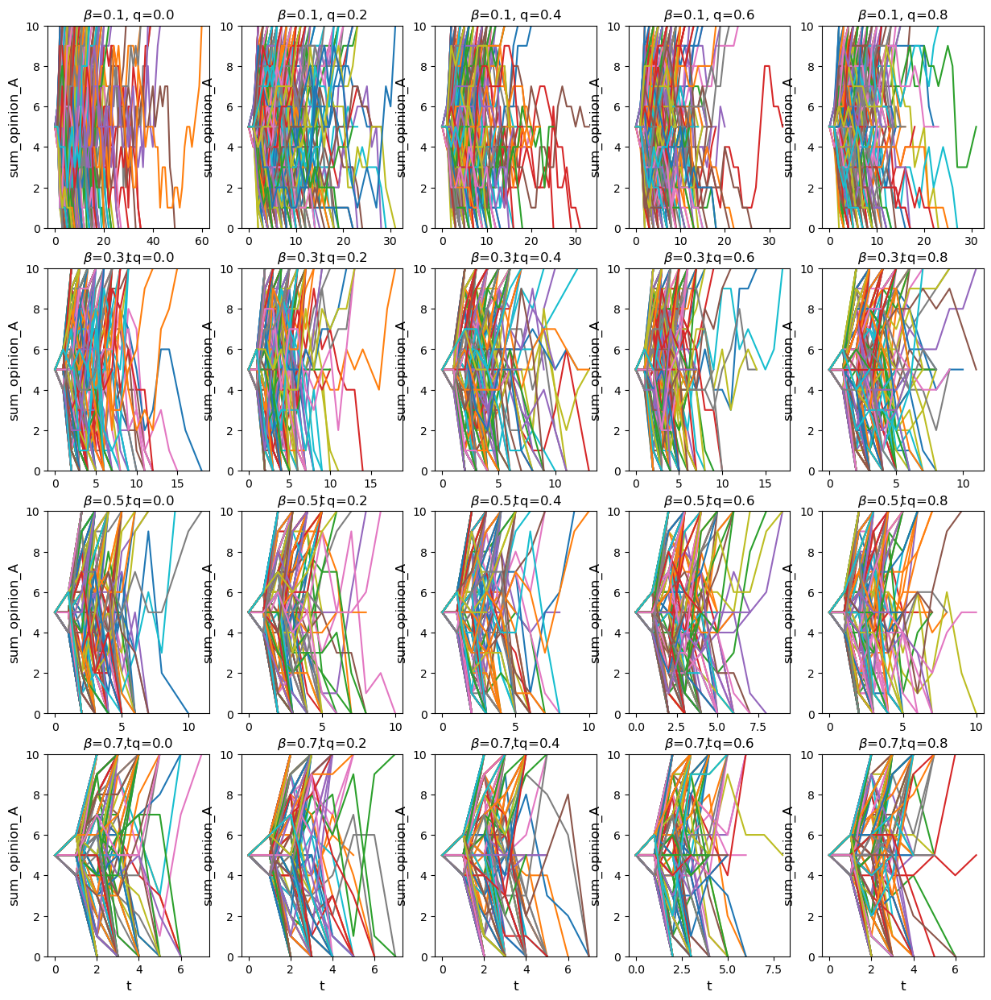

In [75]:
plot_time_dynamic(data,'sum_opinion_A',betas,qs,r'$\beta$','q',(0,10))

In [99]:
def endstates(data,param1s,param2s,name1,name2,row='sum_opinion_A', color_i=0):
    fig, axes = plt.subplots(5,5, figsize=(15,15))
    axes=axes.flatten()
    k=0
    for i in range(0,len(param1s),2):
        for j in range(0,len(param2s),2):
            results=data[i][j]
            ax=axes[k]
            p1=param1s[i]
            p2=param2s[j]
            data_mean=[]
            data_error=[]
            #print(beta,q)
            ax.set_title(f'{name1}={p1:.1f}, {name2}={p2:.1f}',fontsize=fs)
            datas=[results[it][row][-1] for it in range(100)]
            data_count=np.zeros(11)
            for x in datas:
                data_count[x]+=1

            ax.bar(np.arange(11), data_count, 0.8, label=None, color=colors[color_i],edgecolor = 'black', capsize=4,)
            # Customize the second subplot
            ax.set_ylim(0,80)
            ax.set_ylabel(f'count', fontsize=fs)
            ax.set_xlabel(r'# persons on opinion A at end', fontsize=fs)
            ax.set_xticks(np.arange(11))
            ax.tick_params(axis='both', labelsize=ts)# Example categories
            
            k+=1
    plt.tight_layout()

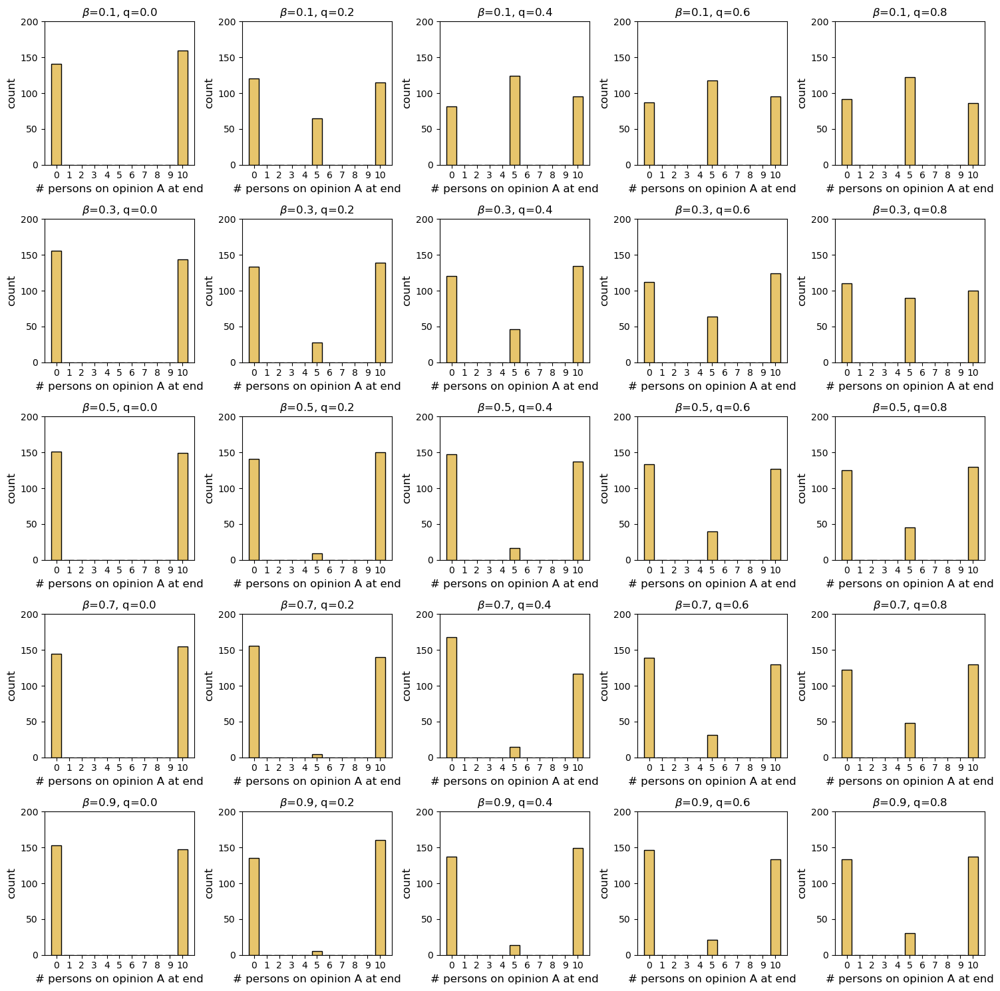

In [79]:
endstates(data,betas,qs,r'$\beta$','q',row='sum_opinion_A', color_i=0)

In [ ]:
def endstates(data,param1s,param2s,name1,name2,row='sum_opinion_A', color_i=0):
    fig, axes = plt.subplots(len(param1s),len(param2s), figsize=(15,15))
    axes=axes.flatten()
    k=0
    for i in range(0,len(param1s)):
        for j in range(0,len(param2s)):
            results=data[i][j]
            ax=axes[k]
            p1=param1s[i]
            p2=param2s[j]
            data_mean=[]
            data_error=[]
            #print(beta,q)
            ax.set_title(f'{name1}={p1:.1f}, {name2}={p2:.1f}',fontsize=fs)
            for it in range(300):
                if results[it][row][-1] ==5:
                    results[it][row]
            data_count=np.zeros(11)
            for x in datas:
                data_count[x]+=1

            ax.bar(np.arange(11), data_count, 0.8, label=None, color=colors[color_i],edgecolor = 'black', capsize=4,)
            # Customize the second subplot
            ax.set_ylim(0,200)
            ax.set_ylabel(f'count', fontsize=fs)
            ax.set_xlabel(r'# persons on opinion A at end', fontsize=fs)
            ax.set_xticks(np.arange(11))
            ax.tick_params(axis='both', labelsize=ts)# Example categories
            
            k+=1
    plt.tight_layout()

In [45]:
import seaborn as sns

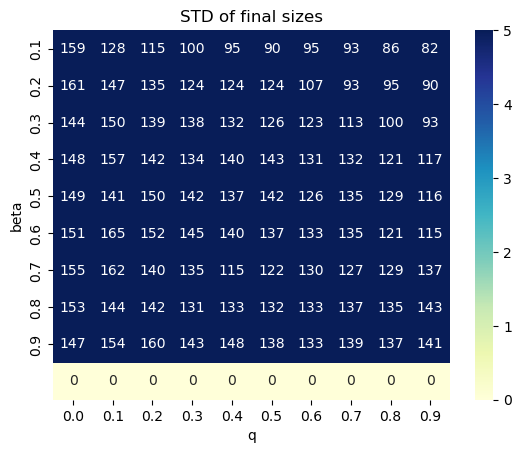

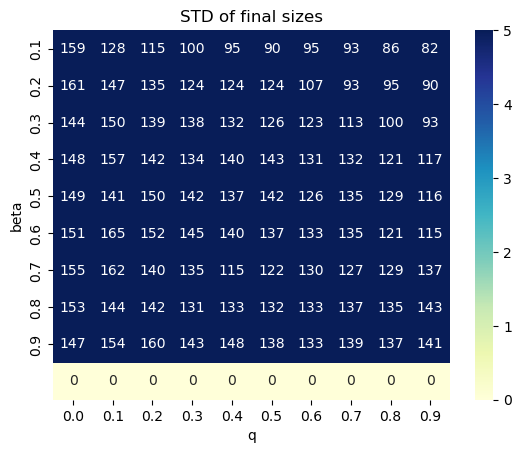

In [88]:
mtx=np.zeros((10,10))
mtx1=np.zeros((10,10))
k=0
for i in range(0,len(betas)):
    for j in range(0,len(qs)):
        s=0
        s1=0
        for it in range(300):
            if data[i][j][it]['sum_opinion_A'][-1] == 10:
                s += int(data[i][j][it]['is_connected'])
                s1+=1
        mtx[i][j]=s
        mtx1[i][j]=s
x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.0f', vmax=5)
plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of final sizes")
plt.show()
sns.heatmap(mtx1,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.0f', vmax=5)


plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of final sizes")
plt.show()

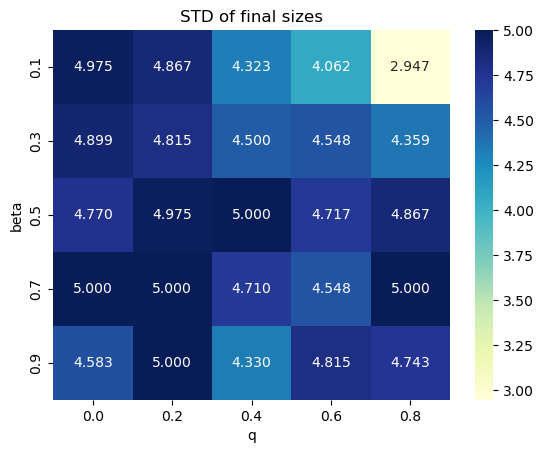

In [20]:
mtx=np.zeros((5,5))
k=0
for i in range(0,len(betas)):
    for j in range(0,len(qs)):
        s = np.std([data[i][j][it]['sum_opinion_A'][-1] for it in range(iterations)])
        
        mtx[i][j]=s
x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=5)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of final sizes")
plt.show()

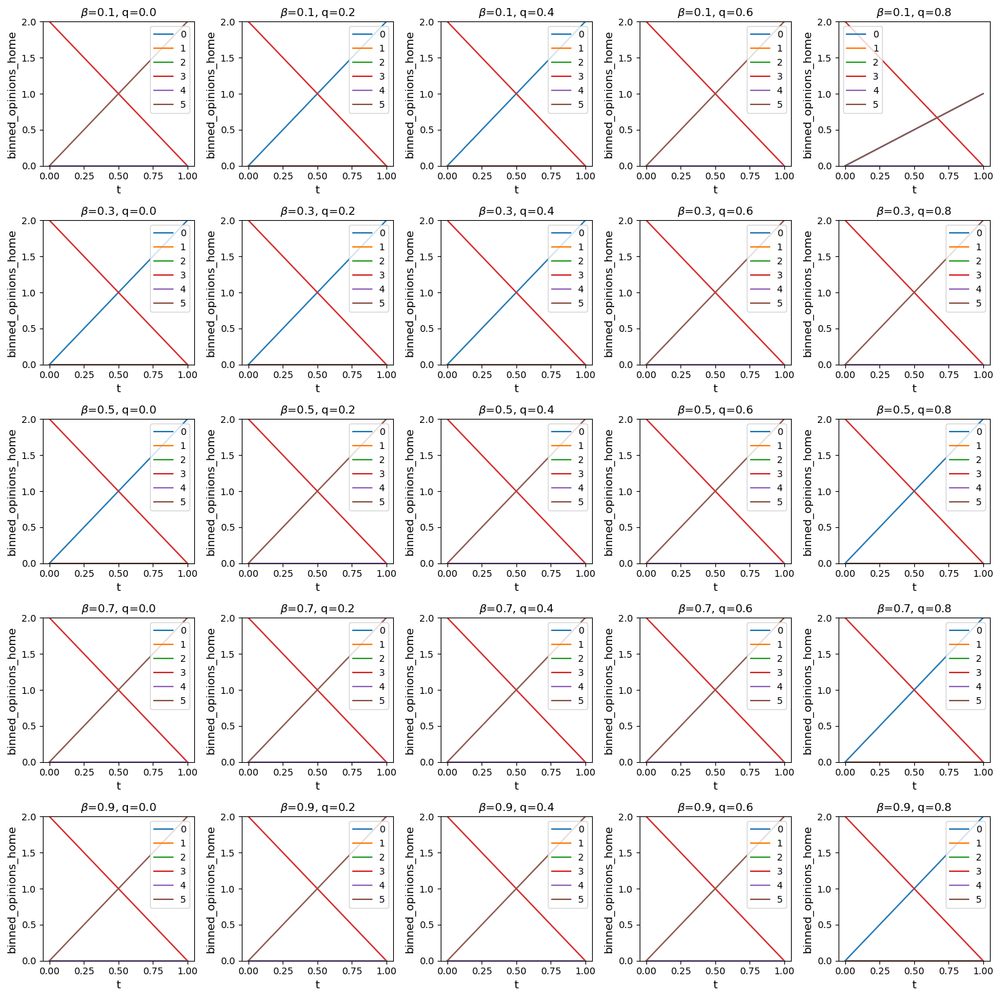

In [23]:
plot_time_dynamic(data,'binned_opinions_home',betas,qs,r'$\beta$','q',(0,2), iters=1,legend =True)

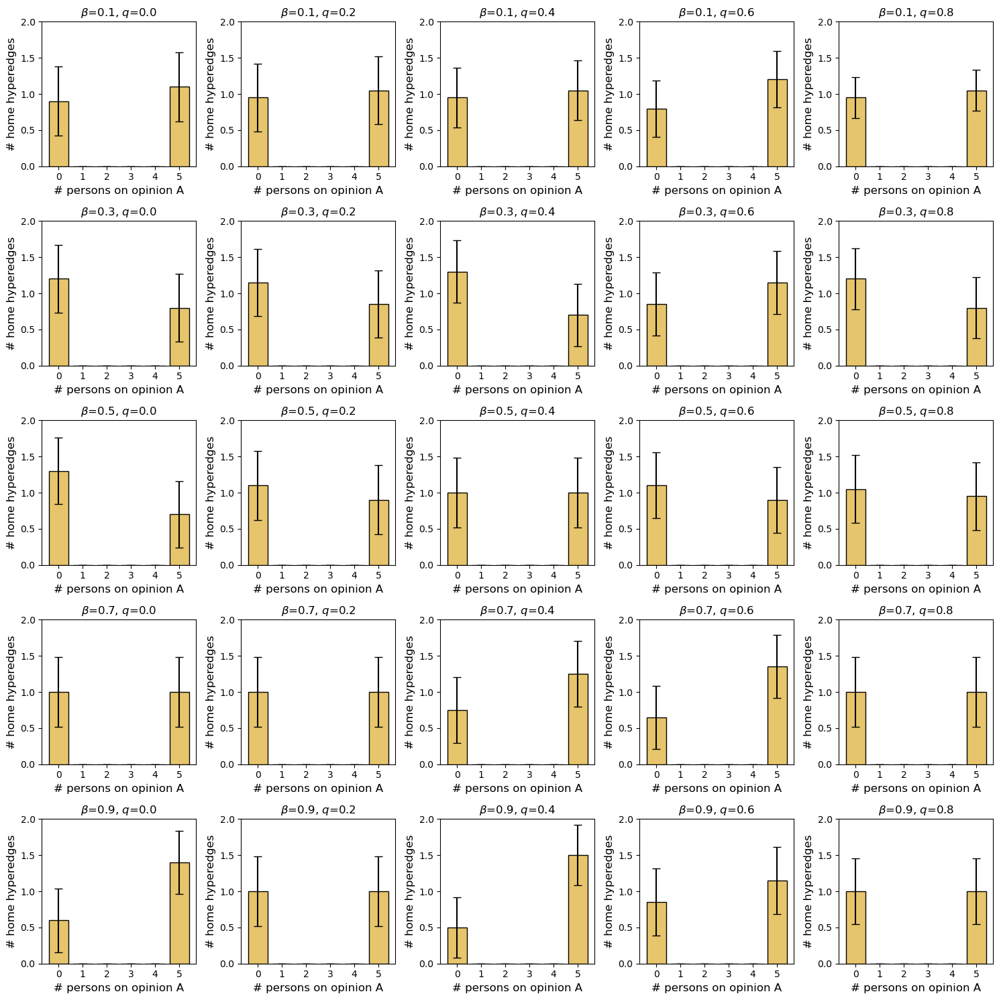

In [27]:
hyperedge_opinions(data,betas,qs,r'$\beta$',r'$q$',row='binned_opinions_home', color_i=0)

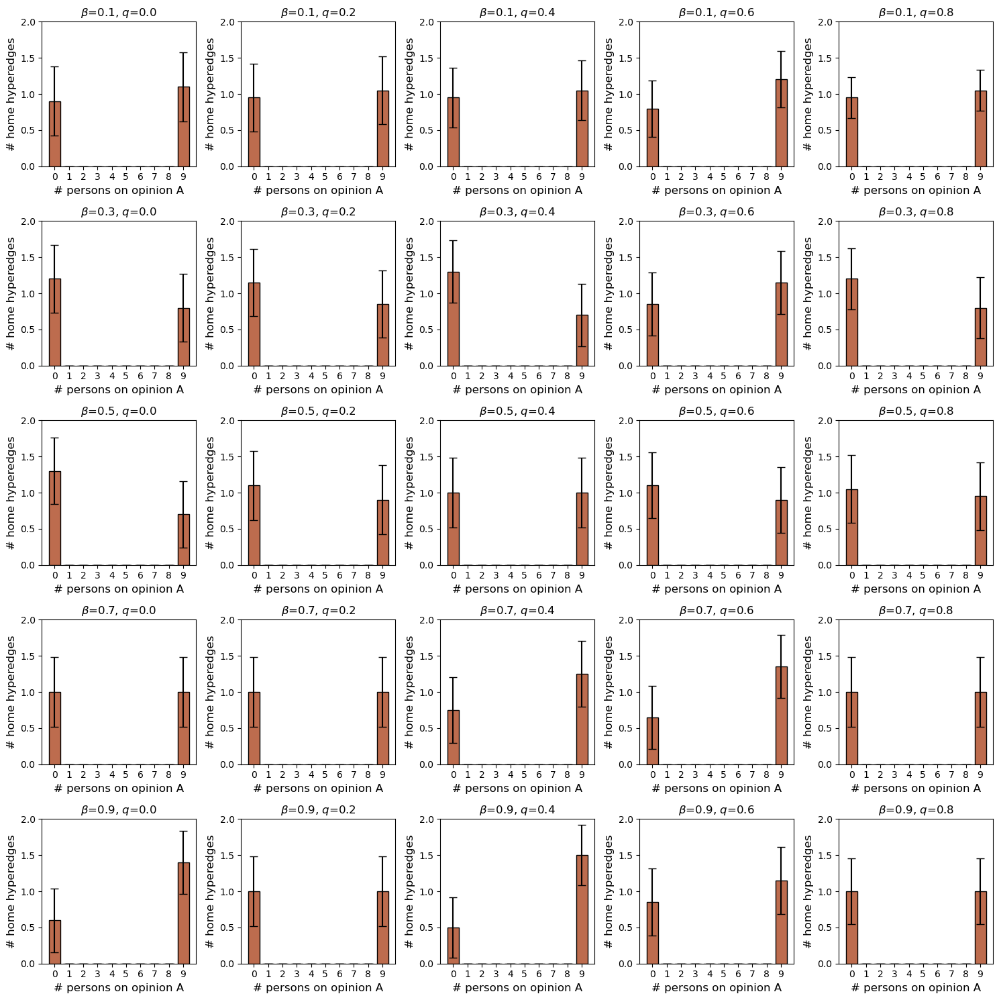

In [28]:
hyperedge_opinions(data,betas,qs,r'$\beta$',r'$q$',row='binned_opinions_wp', color_i=1)

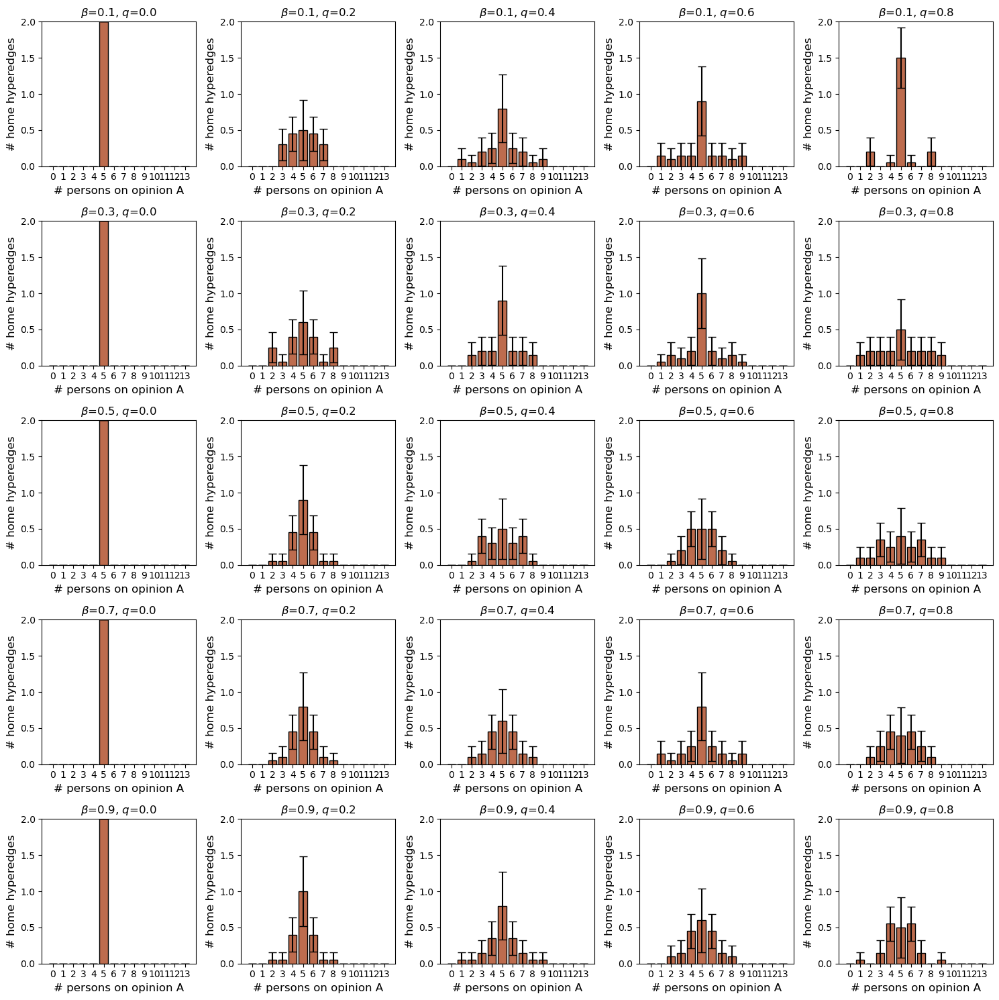

In [29]:
hyperedge_opinions(data,betas,qs,r'$\beta$',r'$q$',row='binned_edge_sizes_wp', color_i=1)

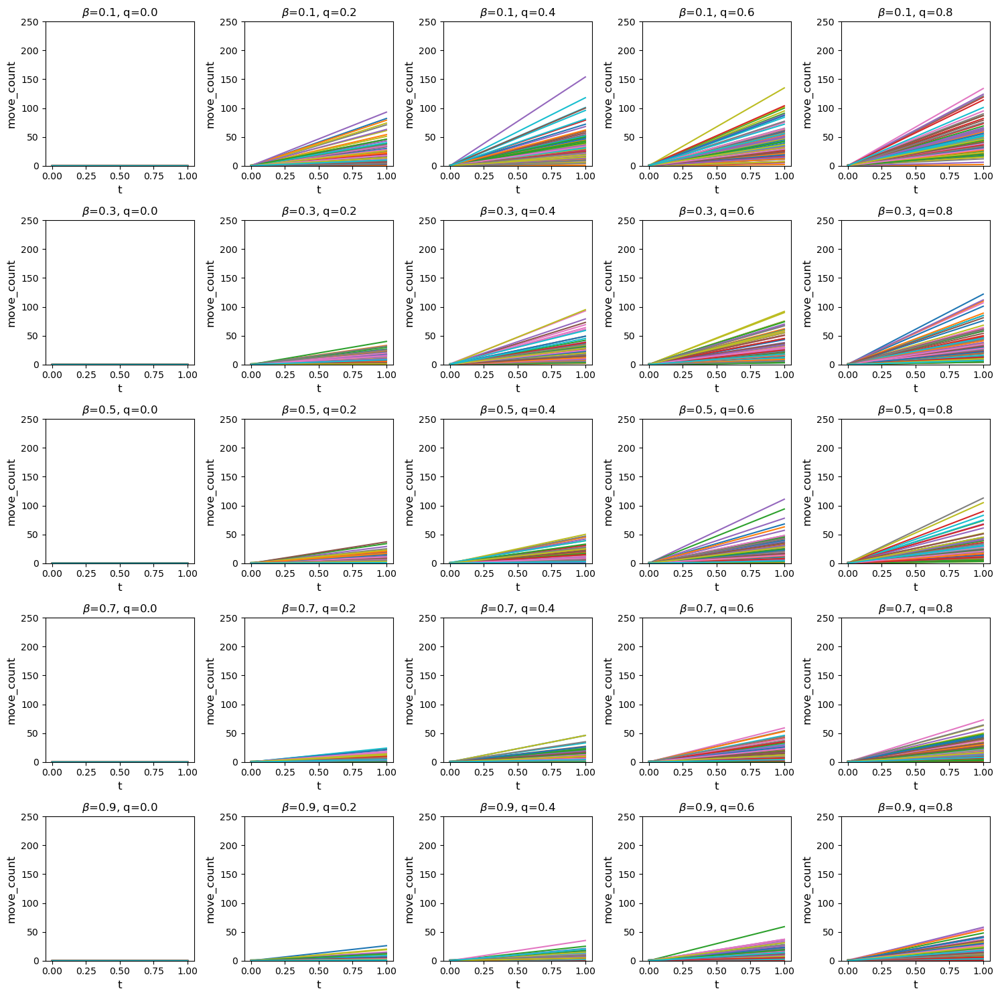

In [30]:
plot_time_dynamic(data,'move_count',betas,qs,r'$\beta$','q',(0,250))

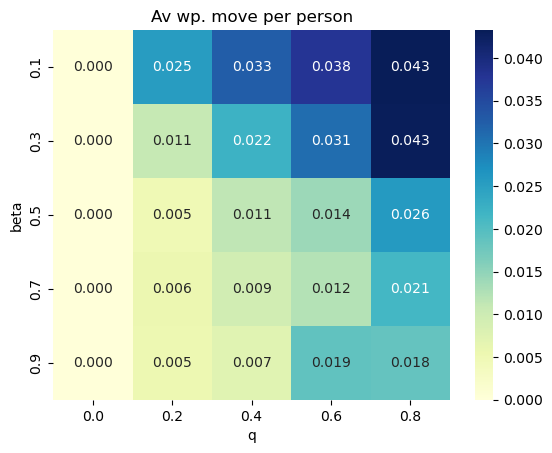

In [32]:
fd_mtx=np.zeros((5,5))
k=0
for i in range(0,len(betas)):
    for j in range(0,len(qs)):
        s = np.mean([np.sum(data[i][j][it]['move_count'])/1000 for it in range(iterations)])
        
        fd_mtx[i][j]=s
x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(fd_mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f')

plt.xlabel("q")
plt.ylabel("beta")
plt.title("Av wp. move per person")
plt.show()

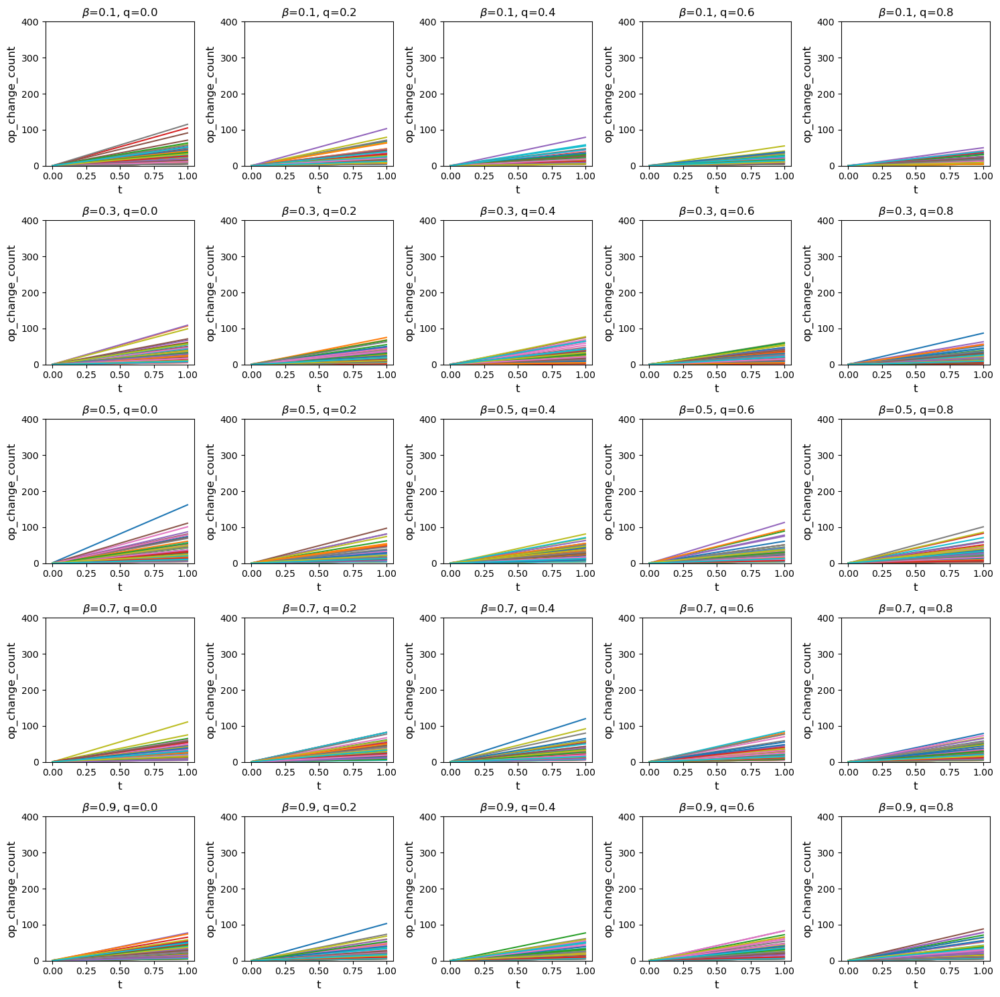

In [31]:
plot_time_dynamic(data,'op_change_count',betas,qs,r'$\beta$','q',(0,400))

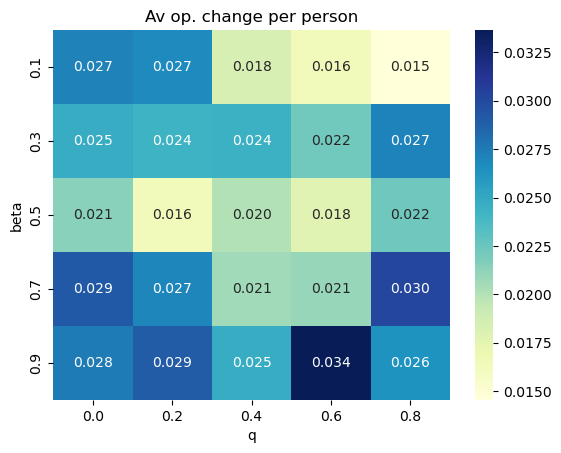

In [33]:
fd_mtx=np.zeros((5,5))
k=0
for i in range(0,len(betas)):
    for j in range(0,len(qs)):
        s = np.mean([np.sum(data[i][j][it]['op_change_count'])/1000 for it in range(iterations)])
        
        fd_mtx[i][j]=s
x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(fd_mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f')

plt.xlabel("q")
plt.ylabel("beta")
plt.title("Av op. change per person")
plt.show()

# Nonlin

In [92]:
filename = 'data/majority_move_nonlin_long10/2_regular_edgesize_5_maj_change_nonlin.pickle'
#import data
with open(filename, 'rb') as handle:
    results_dict = pickle.load(handle)


In [100]:

iterations = 100
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)

In [97]:
data=results_dict

IndexError: index 20 is out of bounds for axis 0 with size 20

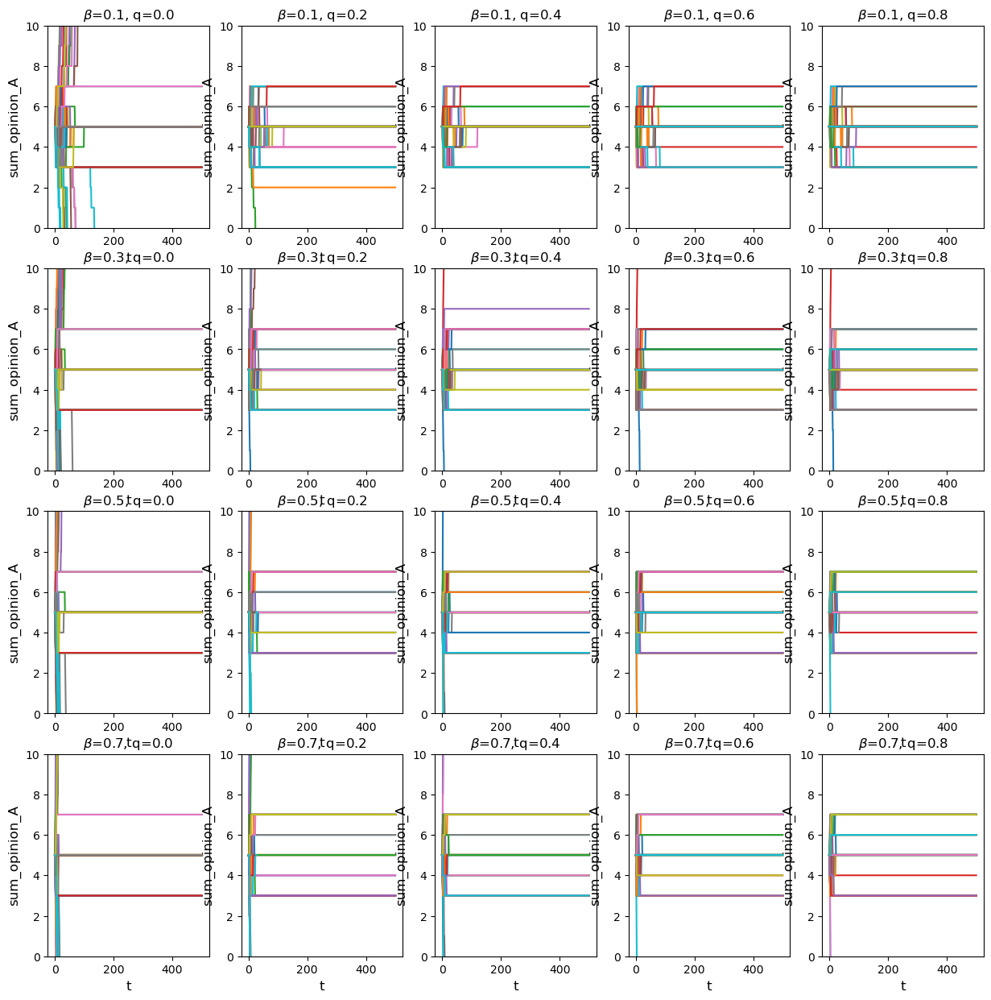

In [101]:
plot_time_dynamic(data,'sum_opinion_A',betas,qs,r'$\beta$','q',(0,10))

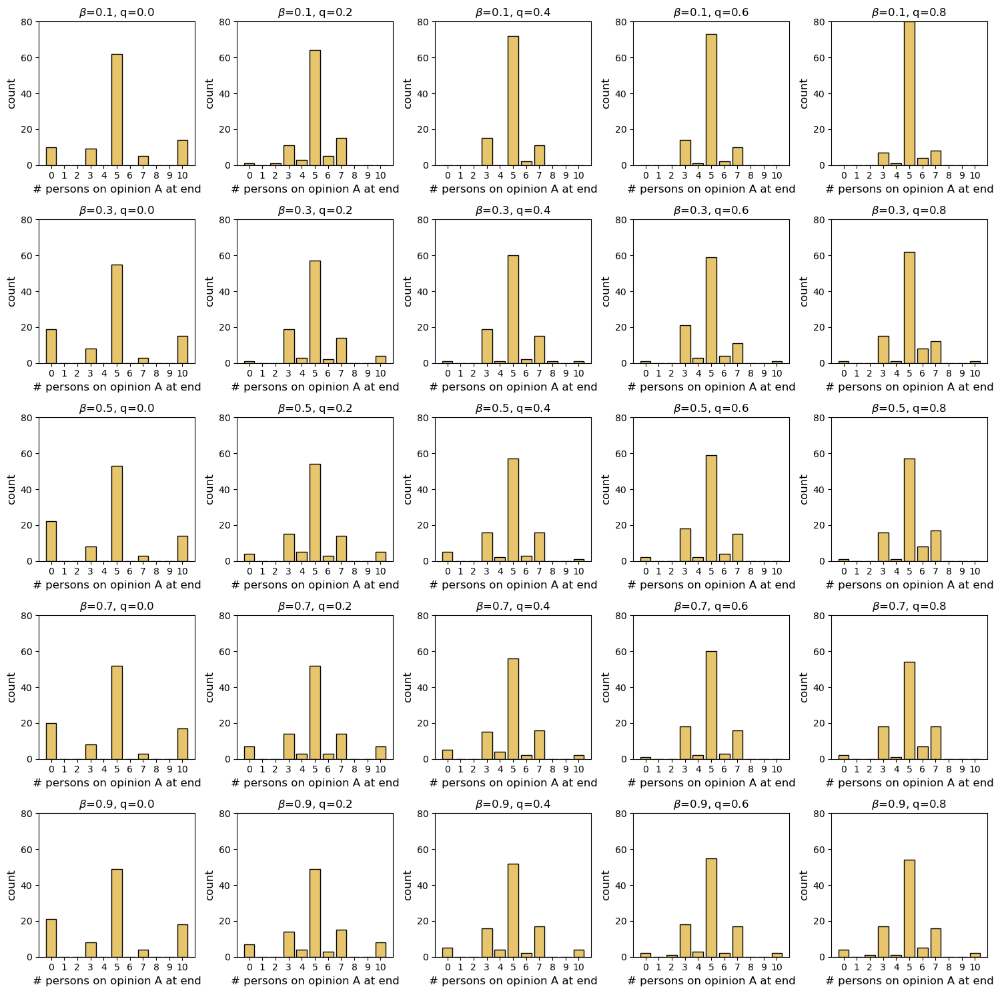

In [102]:
endstates(data,betas,qs,r'$\beta$','q',row='sum_opinion_A', color_i=0)

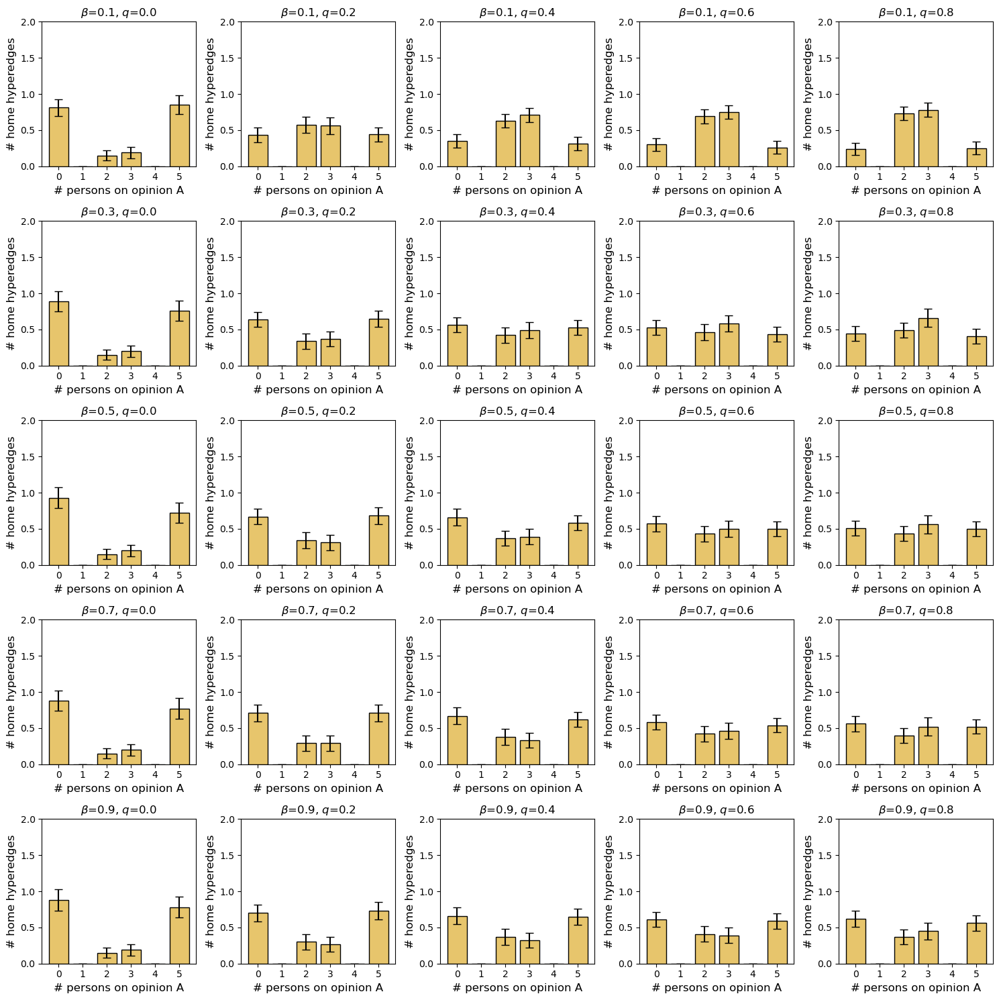

In [103]:
hyperedge_opinions(data,betas,qs,r'$\beta$',r'$q$',row='binned_opinions_home', color_i=0)

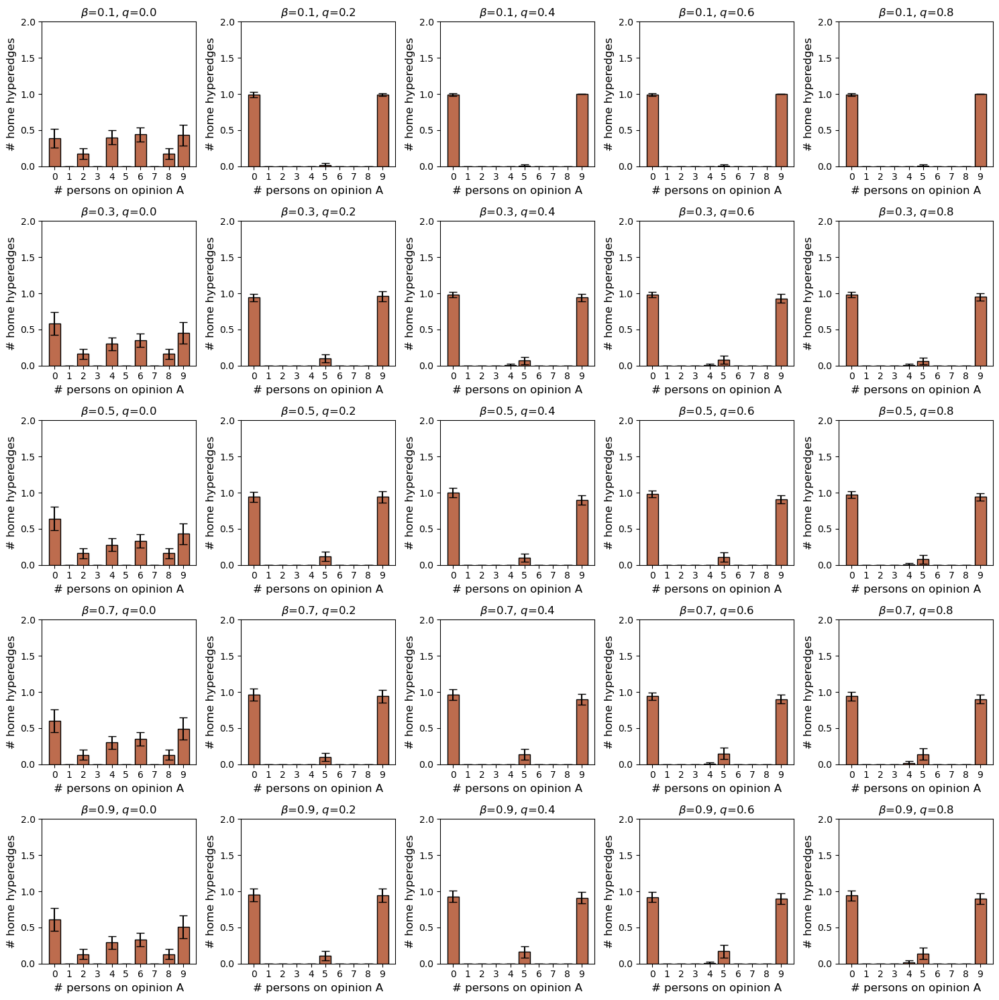

In [104]:
hyperedge_opinions(data,betas,qs,r'$\beta$',r'$q$',row='binned_opinions_wp', color_i=1)

In [48]:
graph_args={'name': 'd_regular', 'args': {'n':1000, 'd':2,'edge size':5, 'distribution':'uniform'}}
data_nonlin = run_parallel(graph_args, betas=np.arange(0.1,1,0.2), 
                    qs=np.arange(0,1,0.2),r1s=[0.5],r2s=[0.5],lambdas=[0.5], 
                    endtime=100000,move='majority', iterations=20, processes=50,
                    log_freq=1000, save=False)

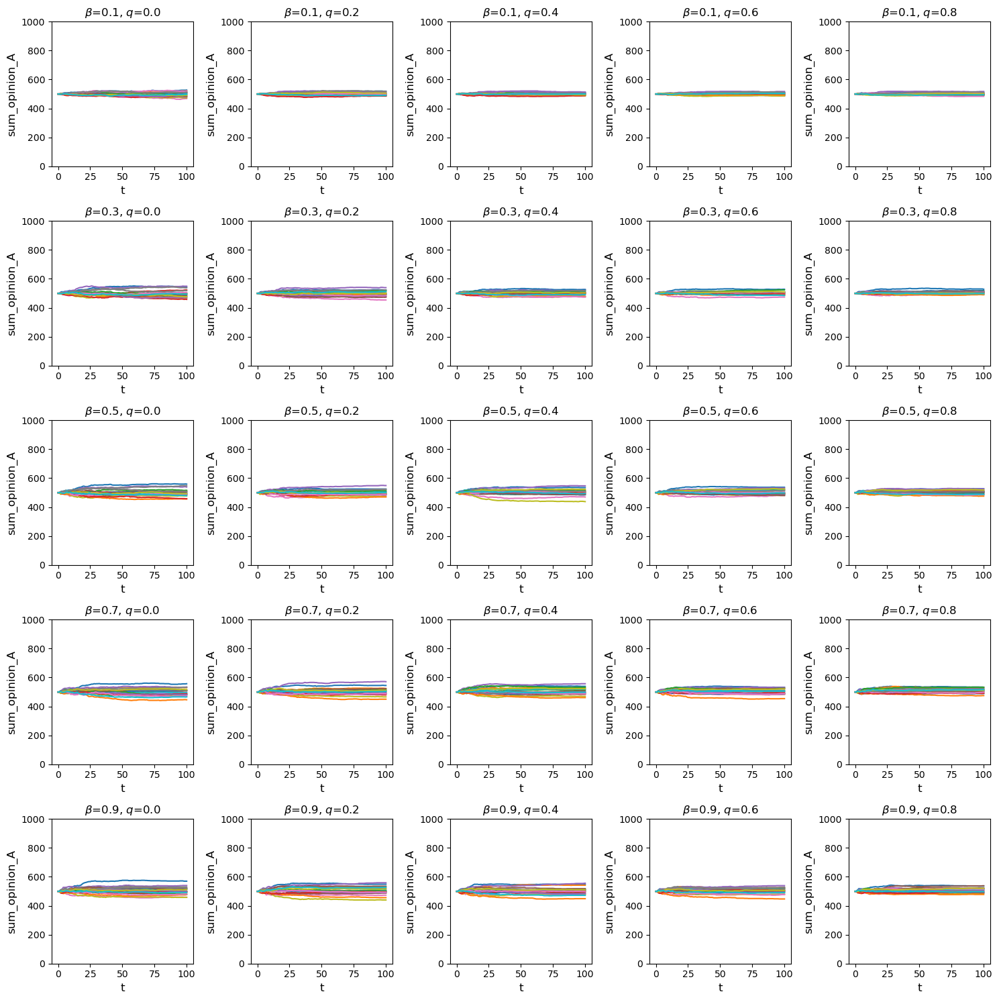

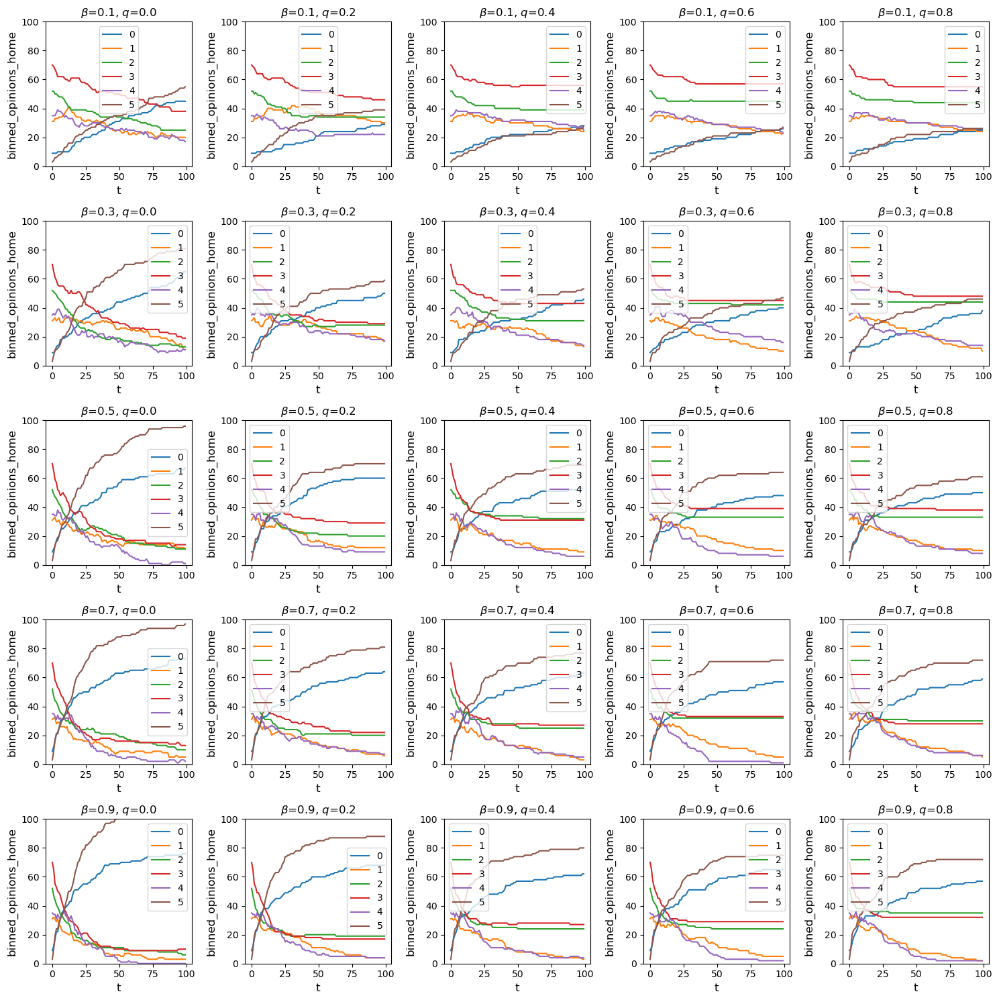

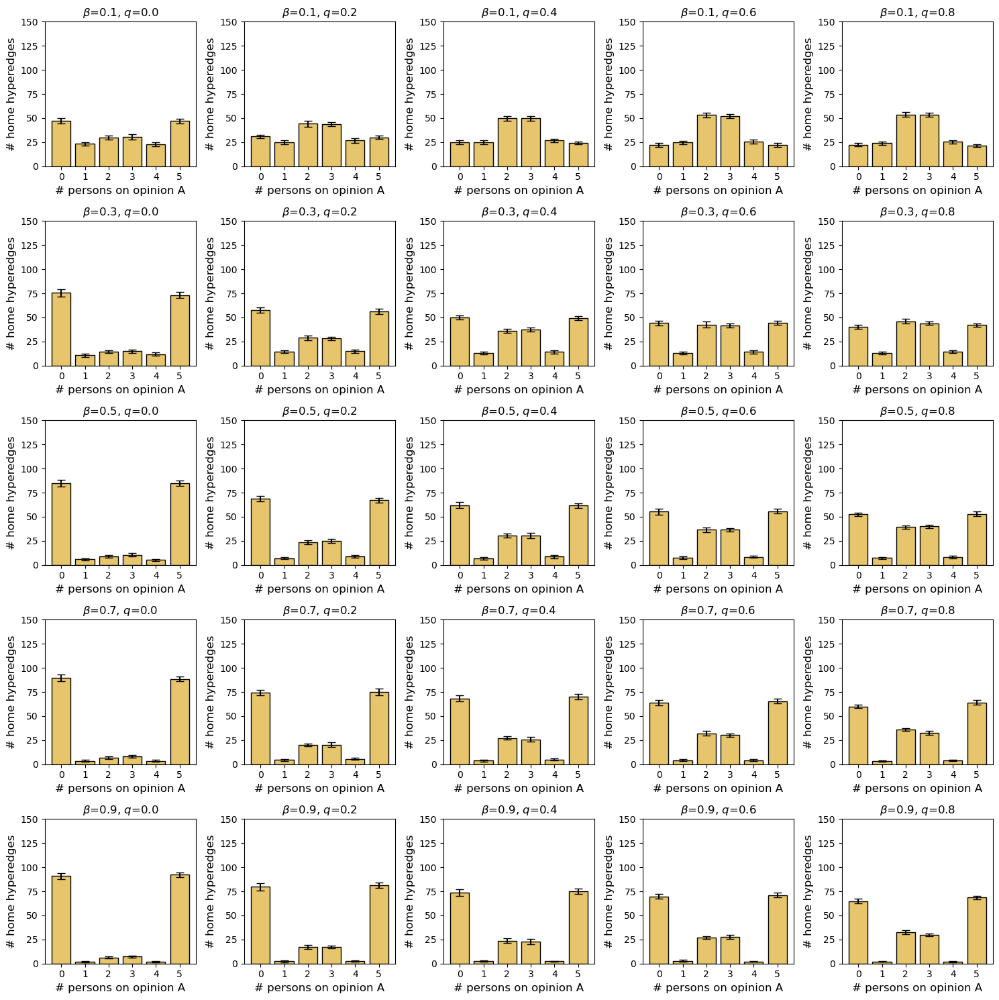

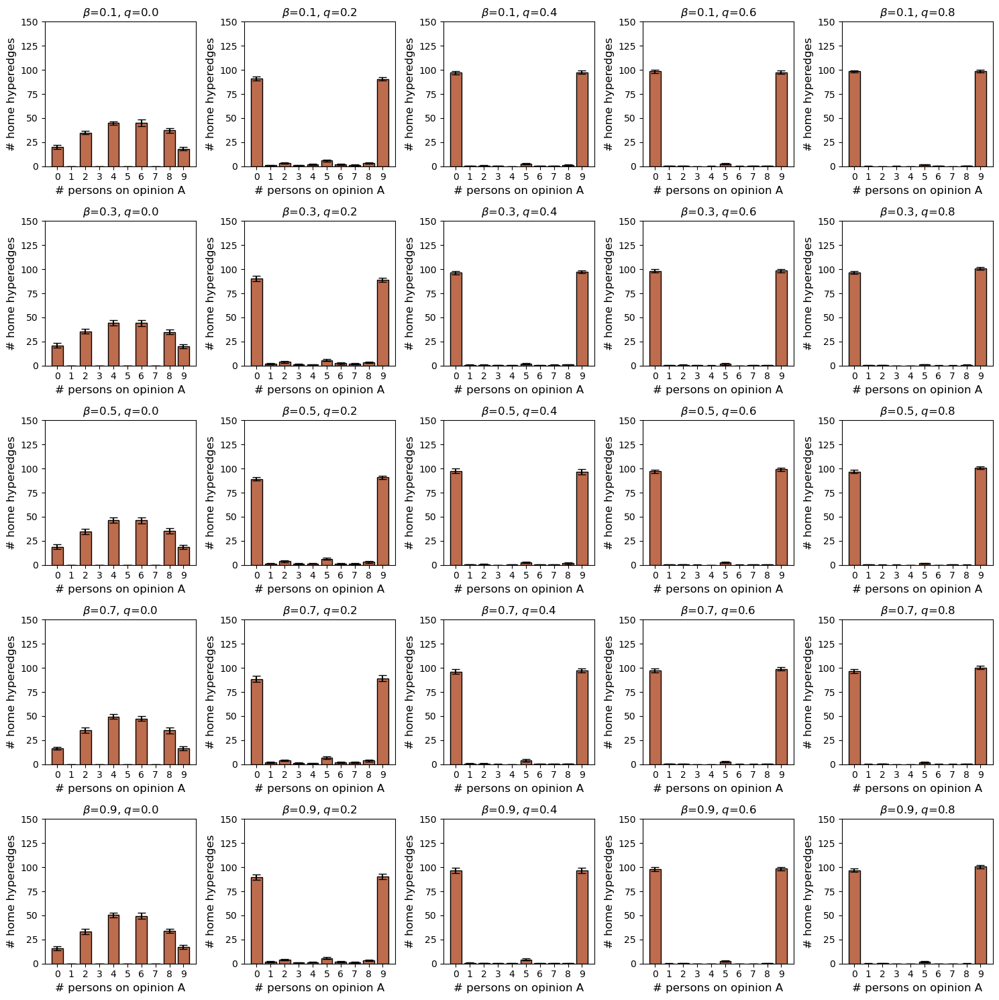

In [51]:
lambdas=np.arange(0,1,0.2)
name2=r'$q$'
plot_time_dynamic(data_nonlin,'sum_opinion_A',betas,qs,r'$\beta$',name2,(0,1000))
plot_time_dynamic(data_nonlin,'binned_opinions_home',betas,qs,r'$\beta$',name2,(0,100), iters=1,legend =True)
hyperedge_opinions(data_nonlin,betas,qs,r'$\beta$',name2,row='binned_opinions_home', color_i=0)
hyperedge_opinions(data_nonlin,betas,qs,r'$\beta$',name2,row='binned_opinions_wp', color_i=1)
#plot_time_dynamic(data_nonlin,'move_count',betas,qs,r'$\beta$',name2,(0,400))
#plot_time_dynamic(data_nonlin,'op_change_count',betas,qs,r'$\beta$',name2,(0,400))
#hyperedge_opinions(data_nonlin,betas,qs,r'$\beta$',name2,row='binned_opinions_wp_pop_sized', color_i=1)


# Discover $r=r_1,r_2$ ; $\beta$

In [12]:
rs=np.arange(0.5,1.05,0.1)

In [13]:
rs

array([0.5, 0.6, 0.7, 0.8, 0.9, 1. ])

In [14]:
graph_args={'name': 'd_regular', 'args': {'n':1000, 'd':2,'edge size':5, 'distribution':'uniform'}}
data_r = run_parallel(graph_args, betas=np.arange(0.1,1,0.2), qs=[0.5],r1s=rs, endtime=100000,move='majority', iterations=20, processes=50,log_freq=1000, save=False)

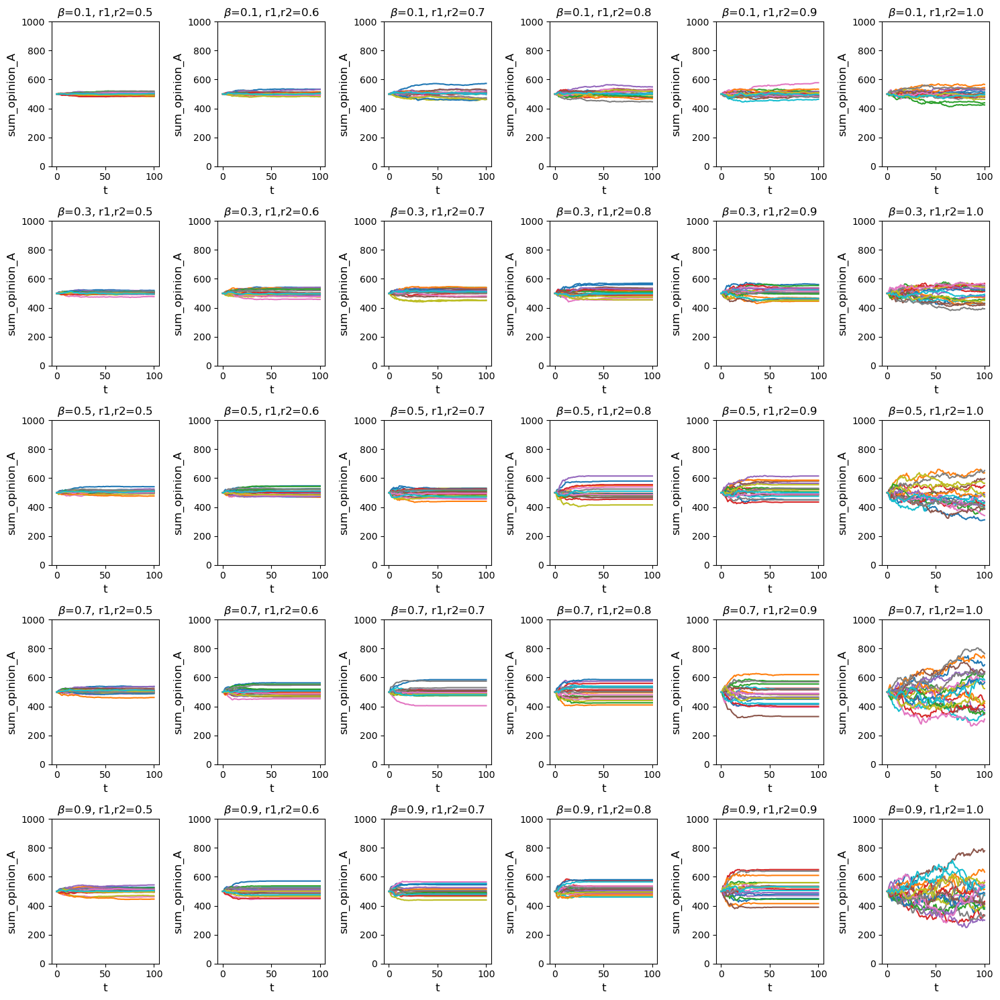

In [15]:
plot_time_dynamic(data_r,'sum_opinion_A',betas,rs,r'$\beta$','r1,r2',(0,1000))

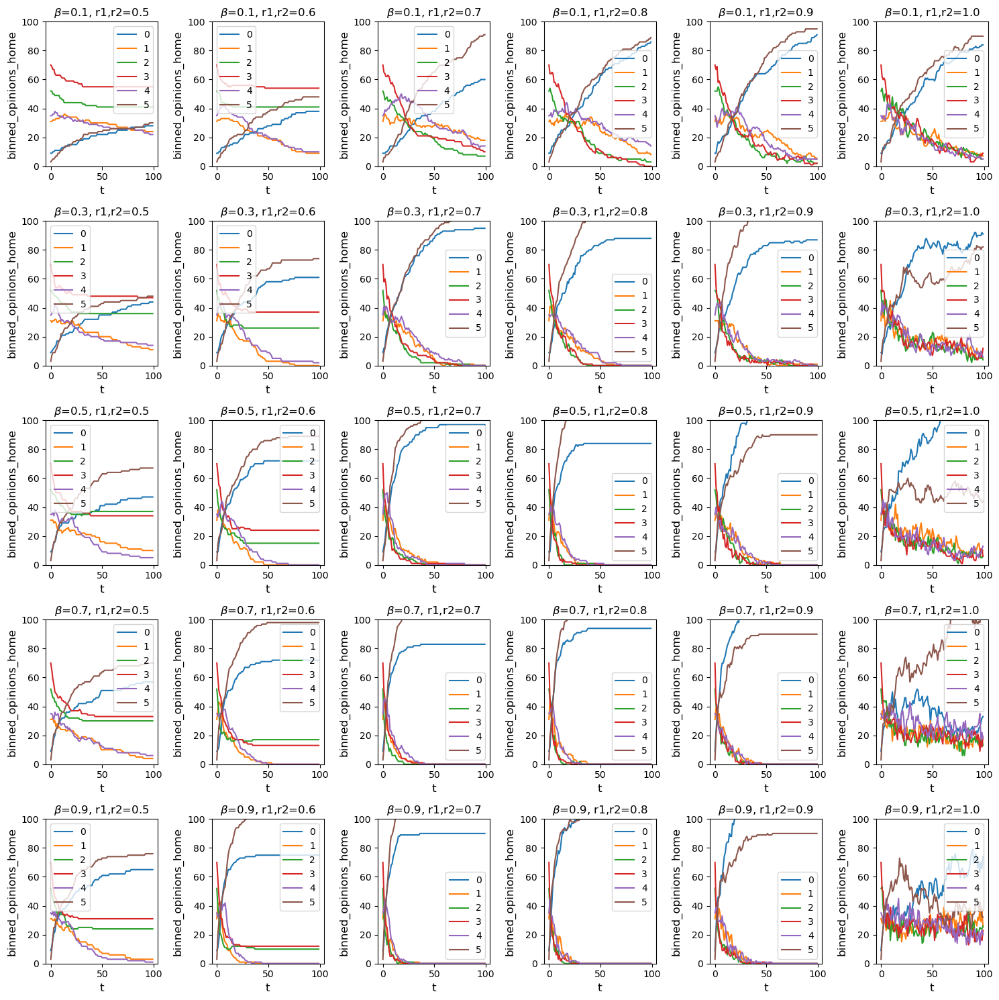

In [18]:
plot_time_dynamic(data_r,'binned_opinions_home',betas,rs,r'$\beta$','r1,r2',(0,100), iters=1,legend =True)

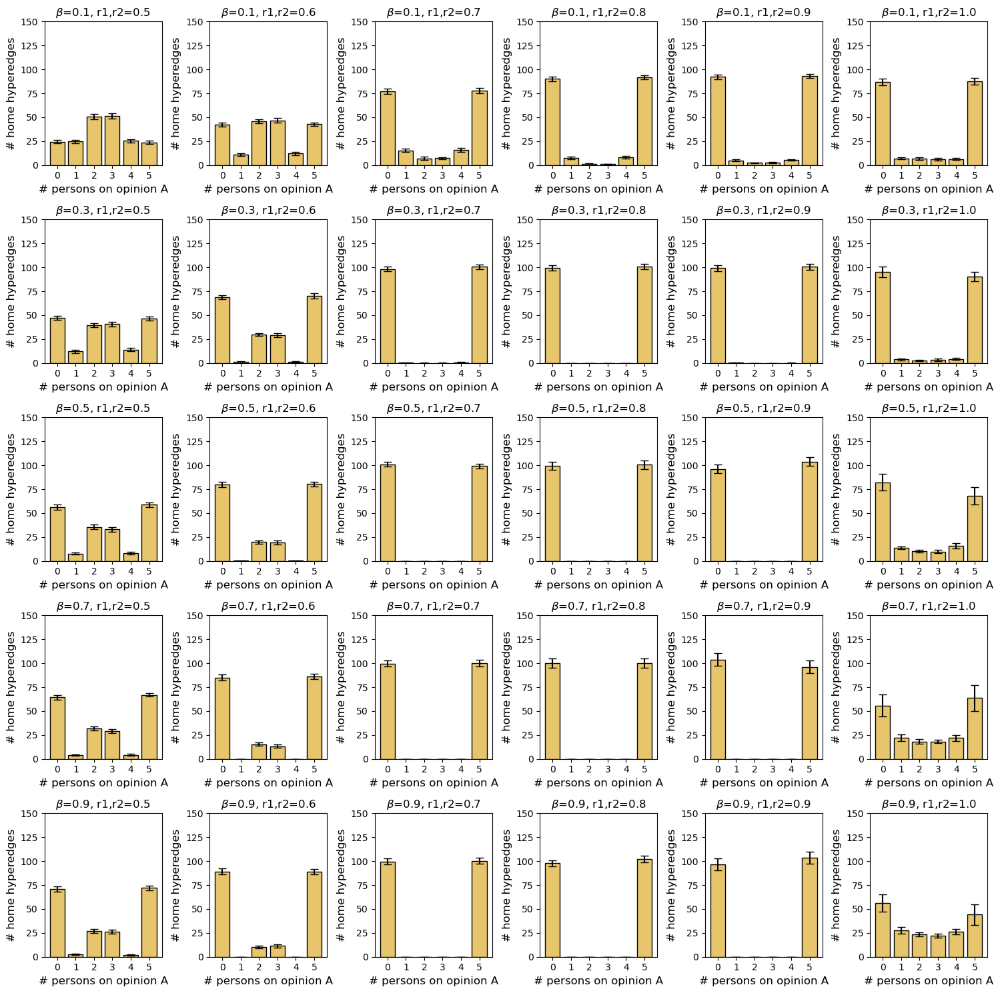

In [32]:
hyperedge_opinions(data_r,betas,rs,r'$\beta$','r1,r2',row='binned_opinions_home', color_i=0)

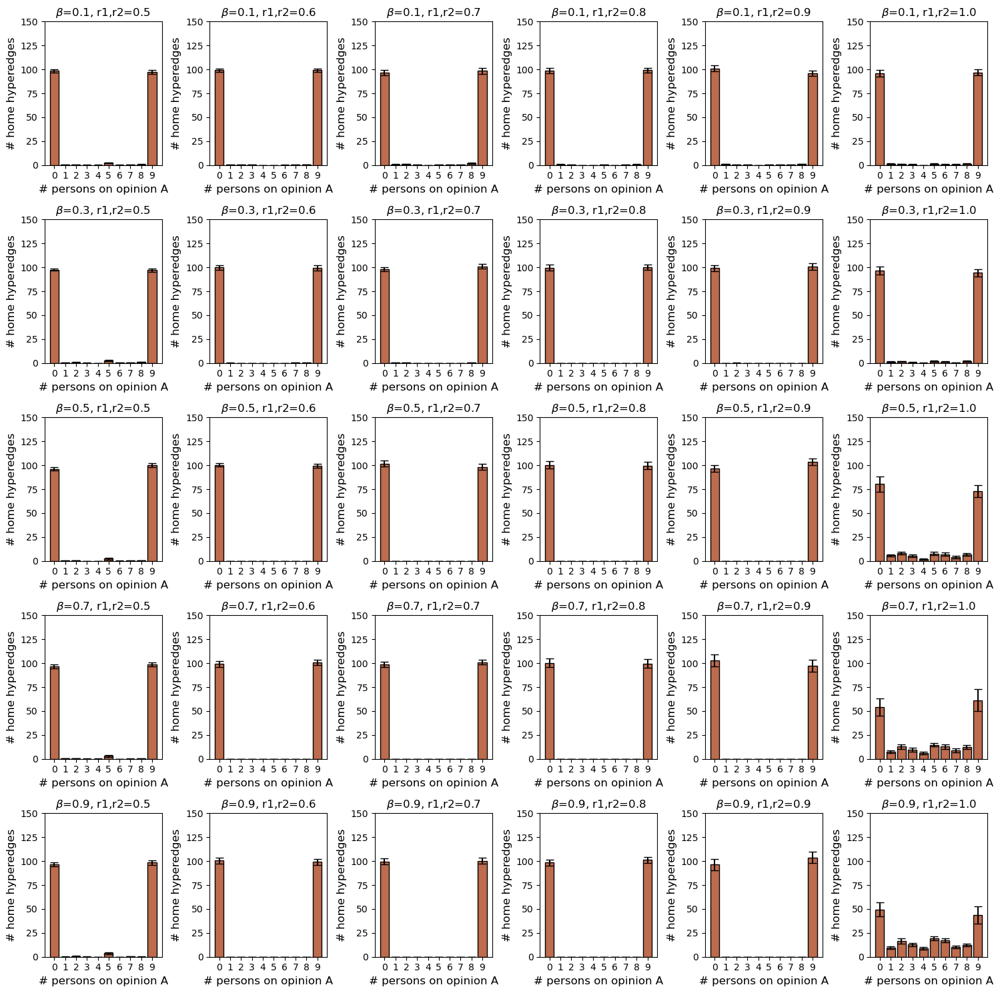

In [33]:
hyperedge_opinions(data_r,betas,rs,r'$\beta$','r1,r2',row='binned_opinions_wp', color_i=1)

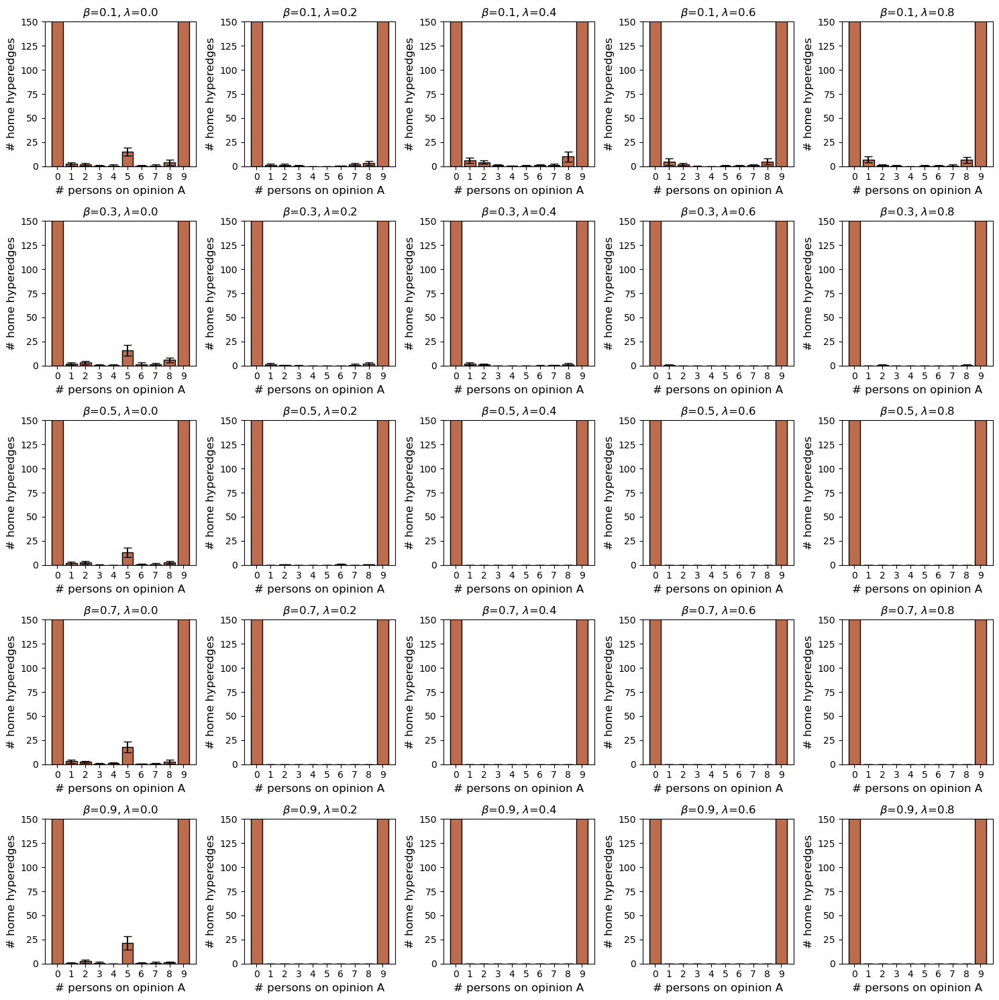

In [44]:
hyperedge_opinions(data_r,betas,lambdas,r'$\beta$',name2,row='binned_opinions_wp_pop_sized', color_i=1)

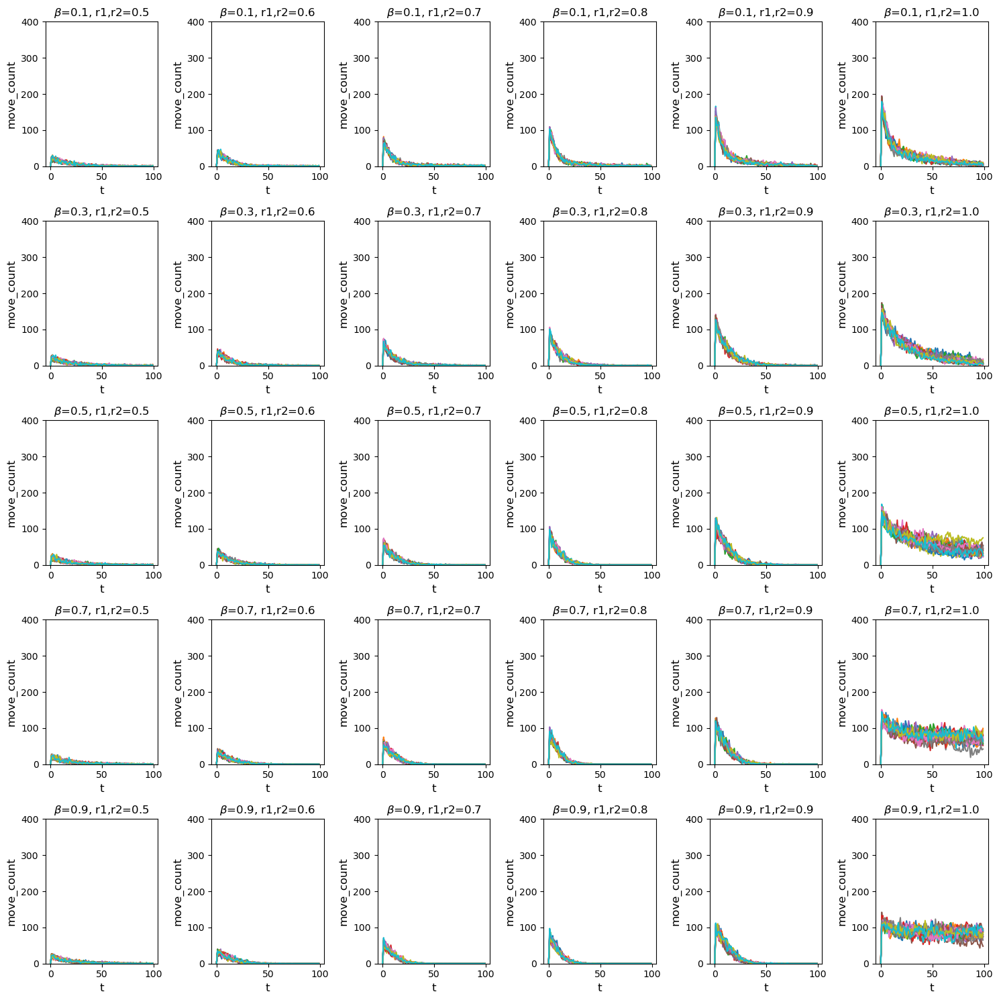

In [24]:
plot_time_dynamic(data_r,'move_count',betas,rs,r'$\beta$','r1,r2',(0,400))

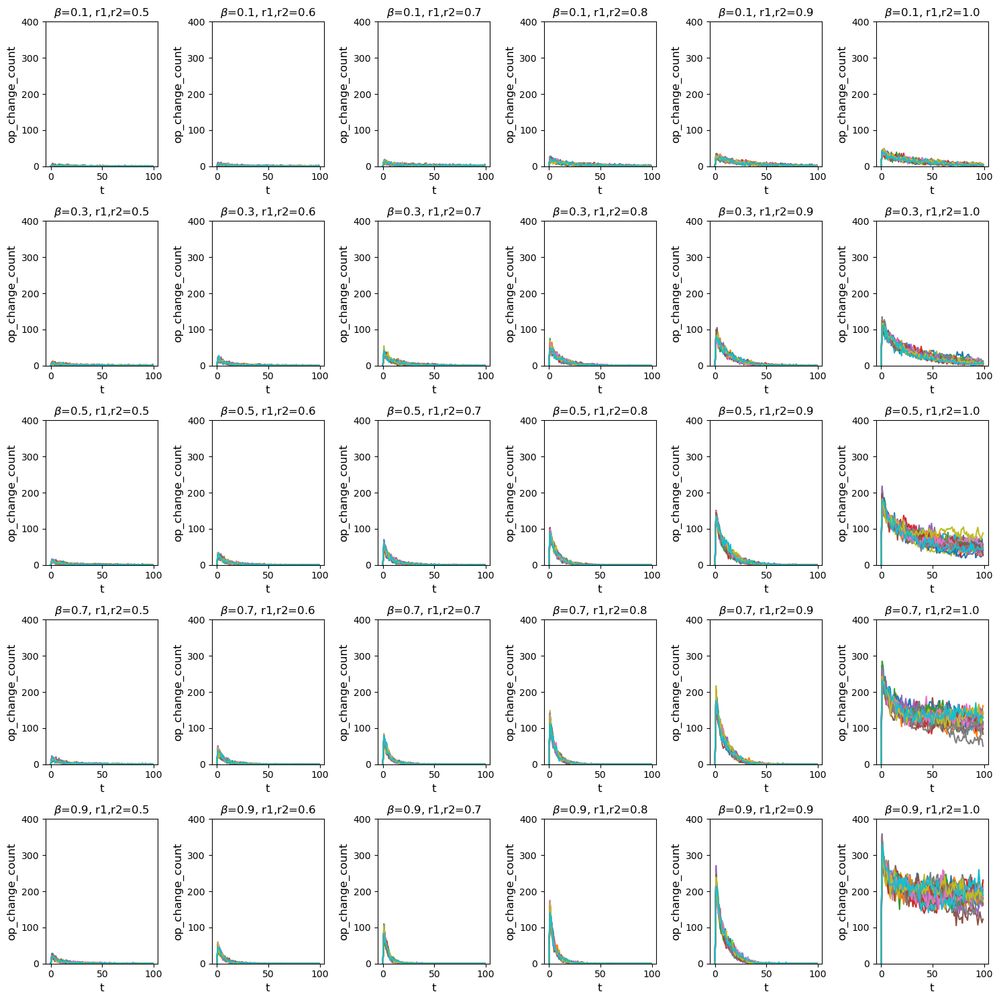

In [25]:
plot_time_dynamic(data_r,'op_change_count',betas,rs,r'$\beta$','r1,r2',(0,400))

# Changing $\lambda$

In [37]:
graph_args={'name': 'd_regular', 'args': {'n':1000, 'd':2,'edge size':5, 'distribution':'uniform'}}
data_l = run_parallel(graph_args, betas=np.arange(0.1,1,0.2), qs=[0.5],r1s=[1], lambdas=np.arange(0,1,0.2), endtime=100000,move='majority', iterations=20, processes=50,log_freq=1000, save=False)

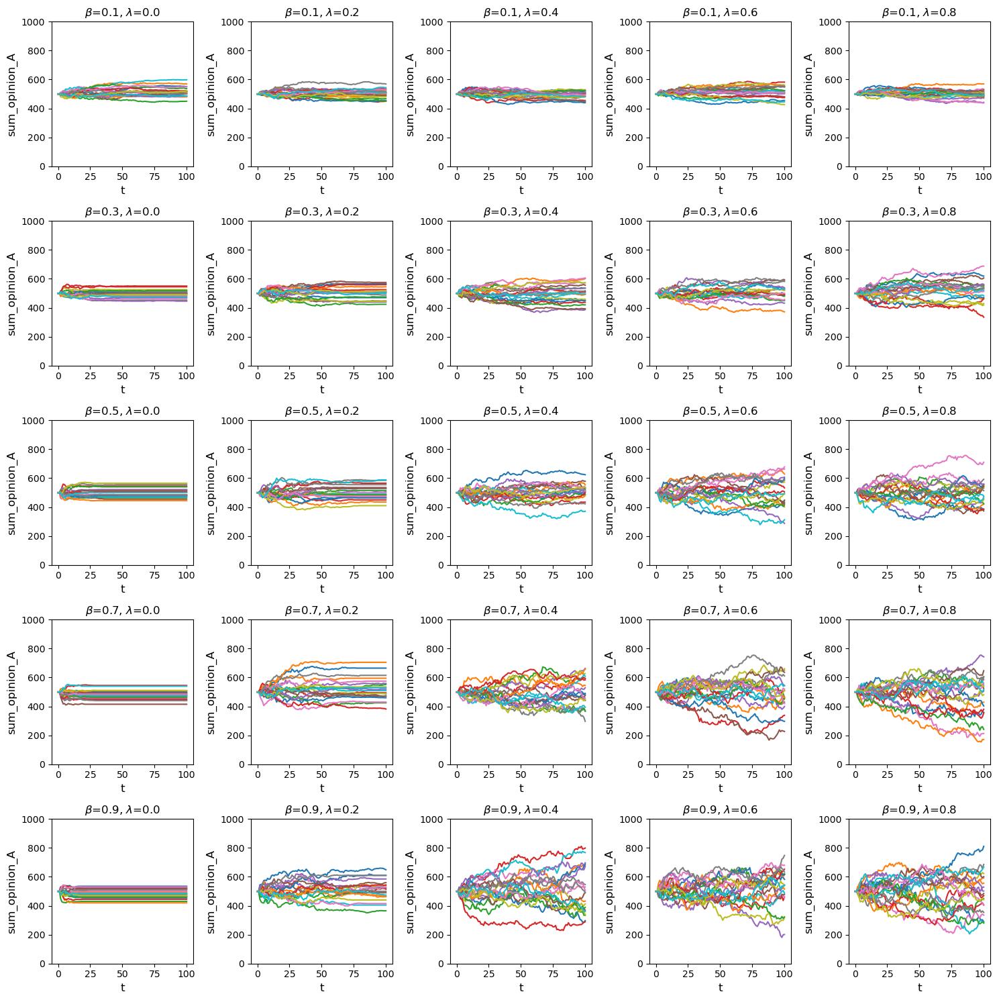

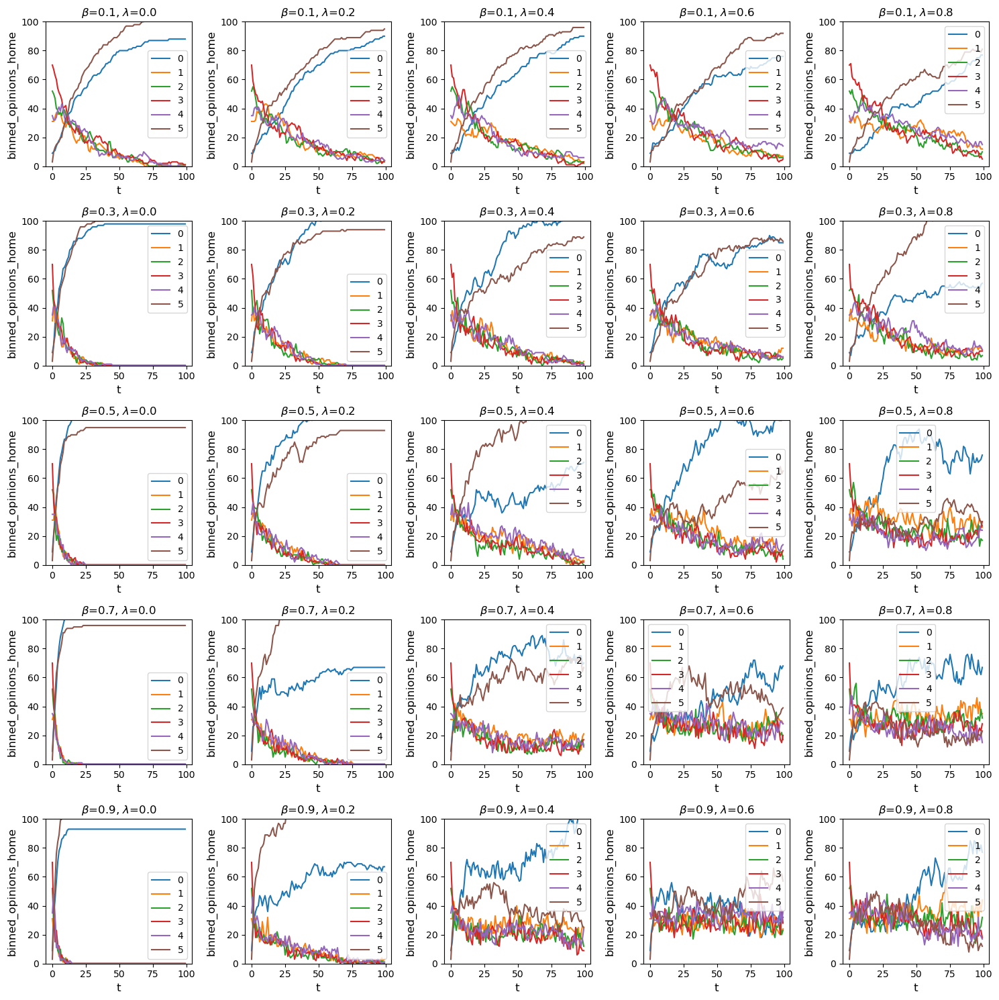

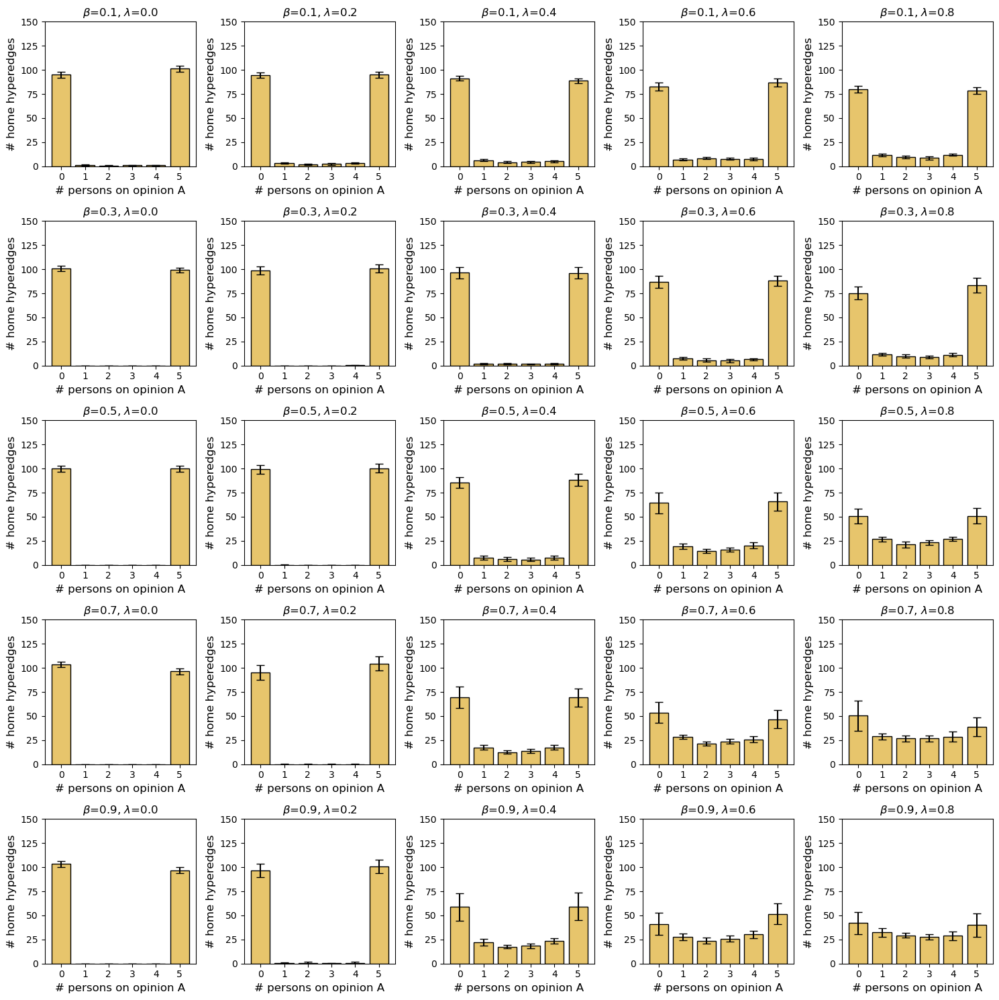

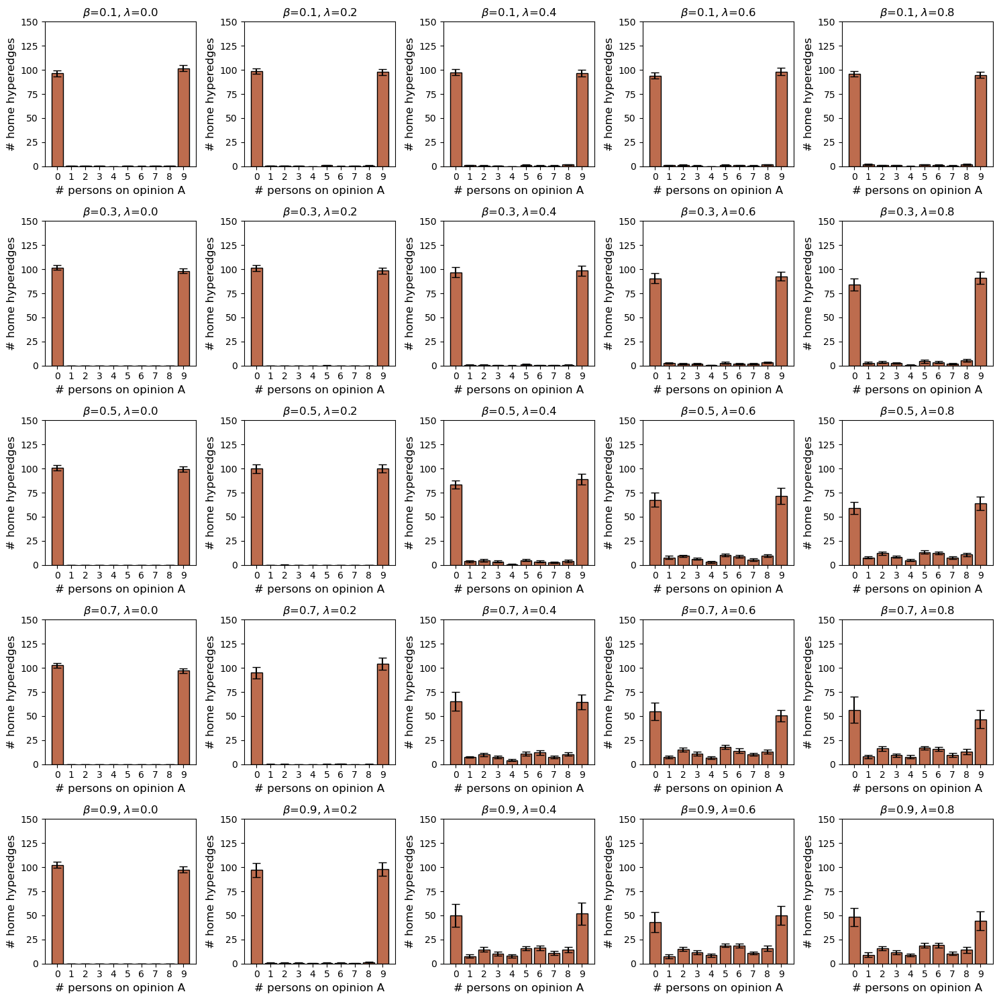

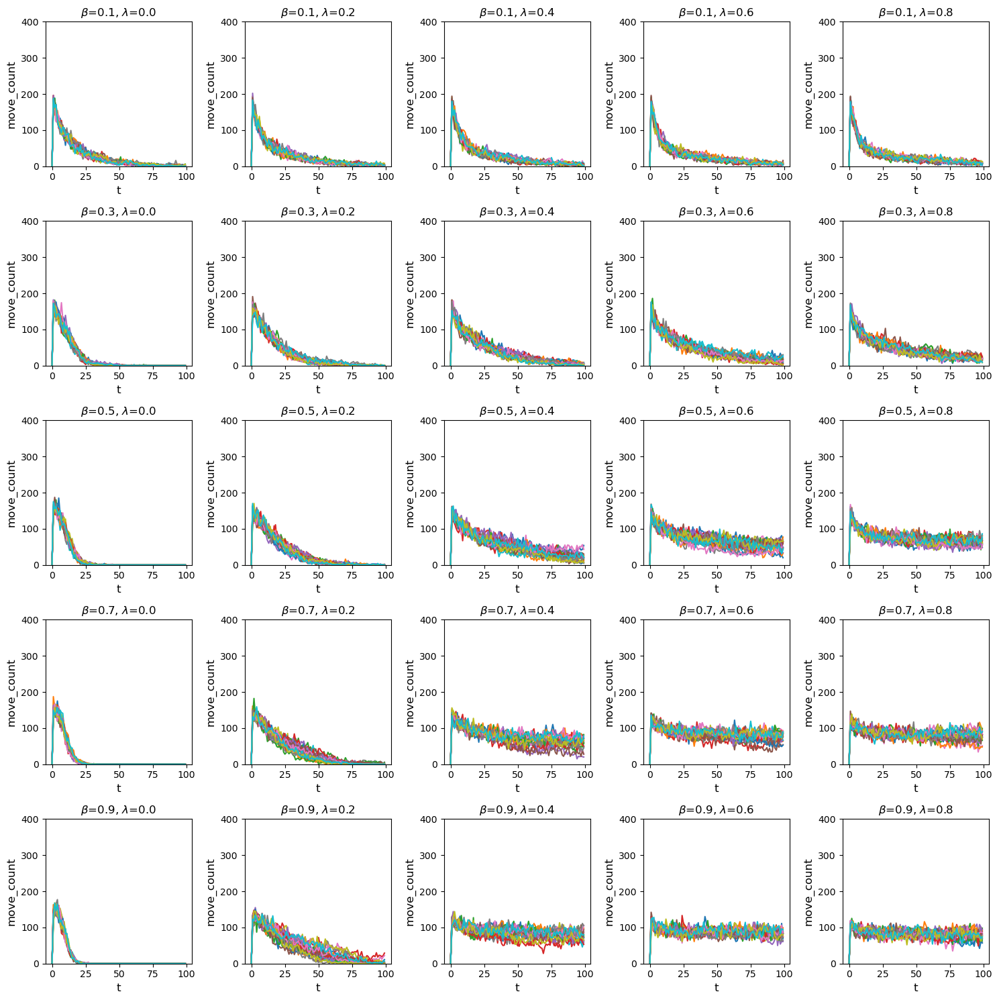

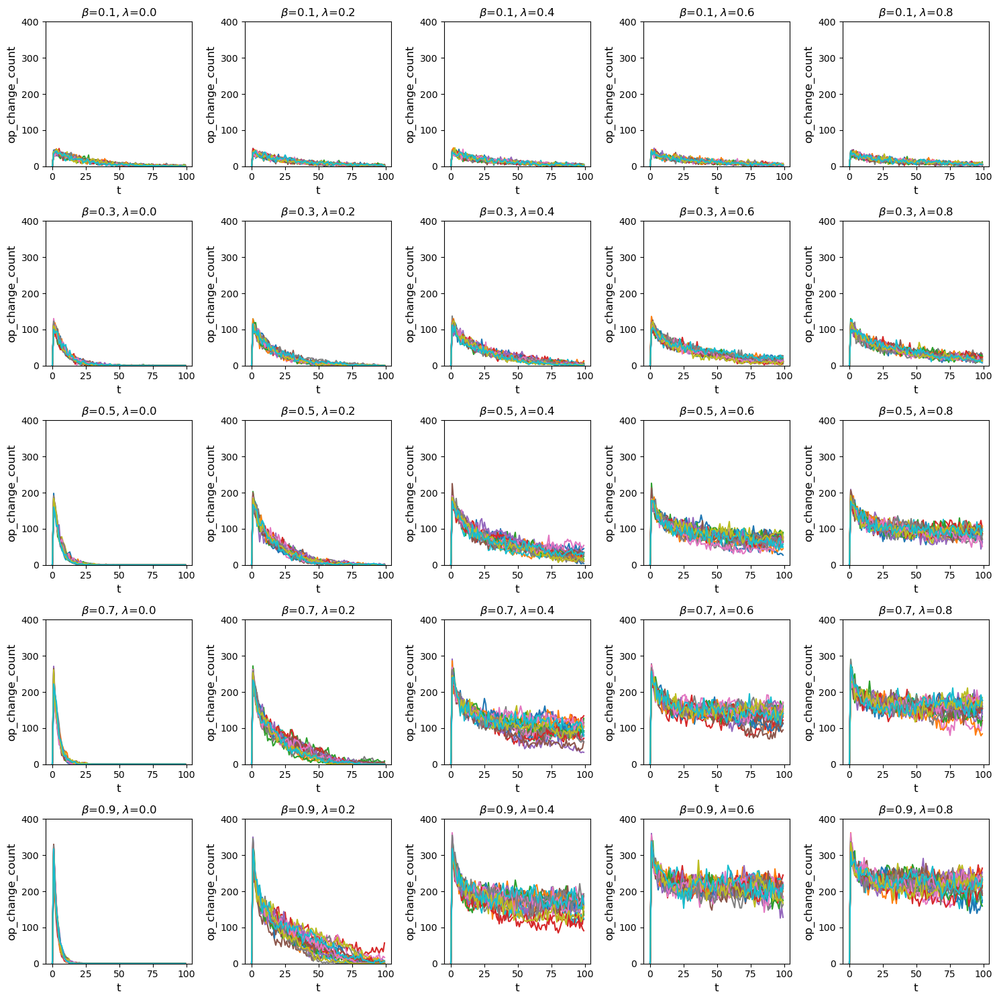

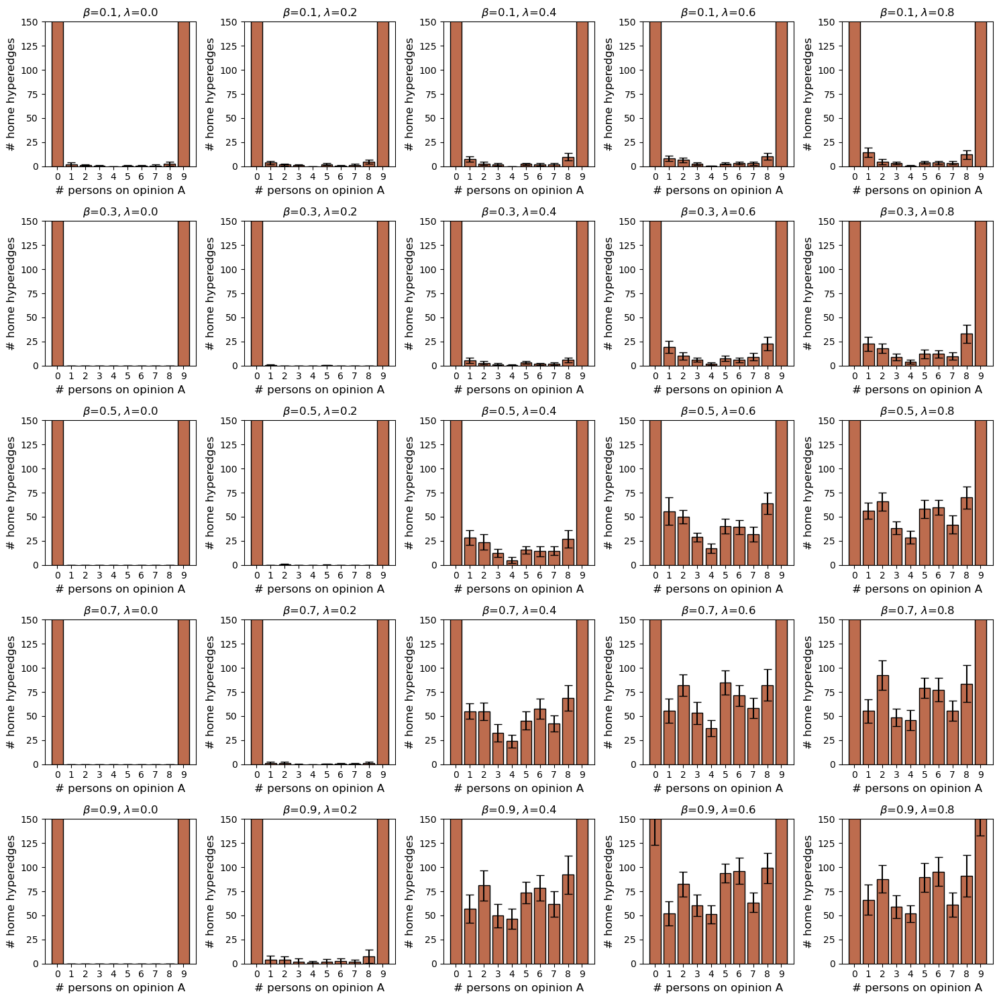

In [45]:
lambdas=np.arange(0,1,0.2)
name2=r'$\lambda$'
plot_time_dynamic(data_l,'sum_opinion_A',betas,lambdas,r'$\beta$',name2,(0,1000))
plot_time_dynamic(data_l,'binned_opinions_home',betas,lambdas,r'$\beta$',name2,(0,100), iters=1,legend =True)
hyperedge_opinions(data_l,betas,lambdas,r'$\beta$',name2,row='binned_opinions_home', color_i=0)
hyperedge_opinions(data_l,betas,lambdas,r'$\beta$',name2,row='binned_opinions_wp', color_i=1)
plot_time_dynamic(data_l,'move_count',betas,lambdas,r'$\beta$',name2,(0,400))
plot_time_dynamic(data_l,'op_change_count',betas,lambdas,r'$\beta$',name2,(0,400))
hyperedge_opinions(data_l,betas,lambdas,r'$\beta$',name2,row='binned_opinions_wp_pop_sized', color_i=1)


In [39]:
graph_args={'name': 'd_regular', 'args': {'n':1000, 'd':2,'edge size':5, 'distribution':'uniform'}}
data_l2 = run_parallel(graph_args, betas=np.arange(0.1,1,0.2), qs=[0.5],r1s=[0.5], lambdas=np.arange(0,1,0.2), endtime=100000,move='majority', iterations=20, processes=50,log_freq=1000, save=False)

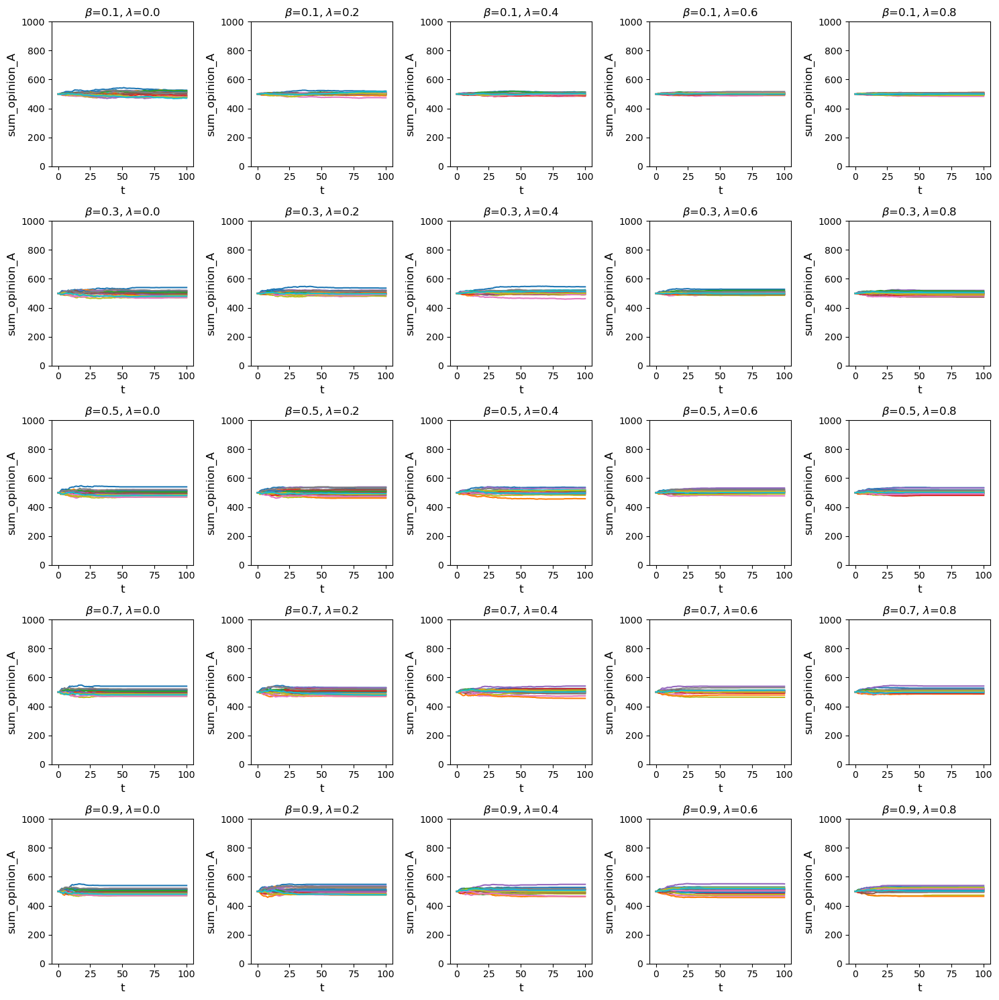

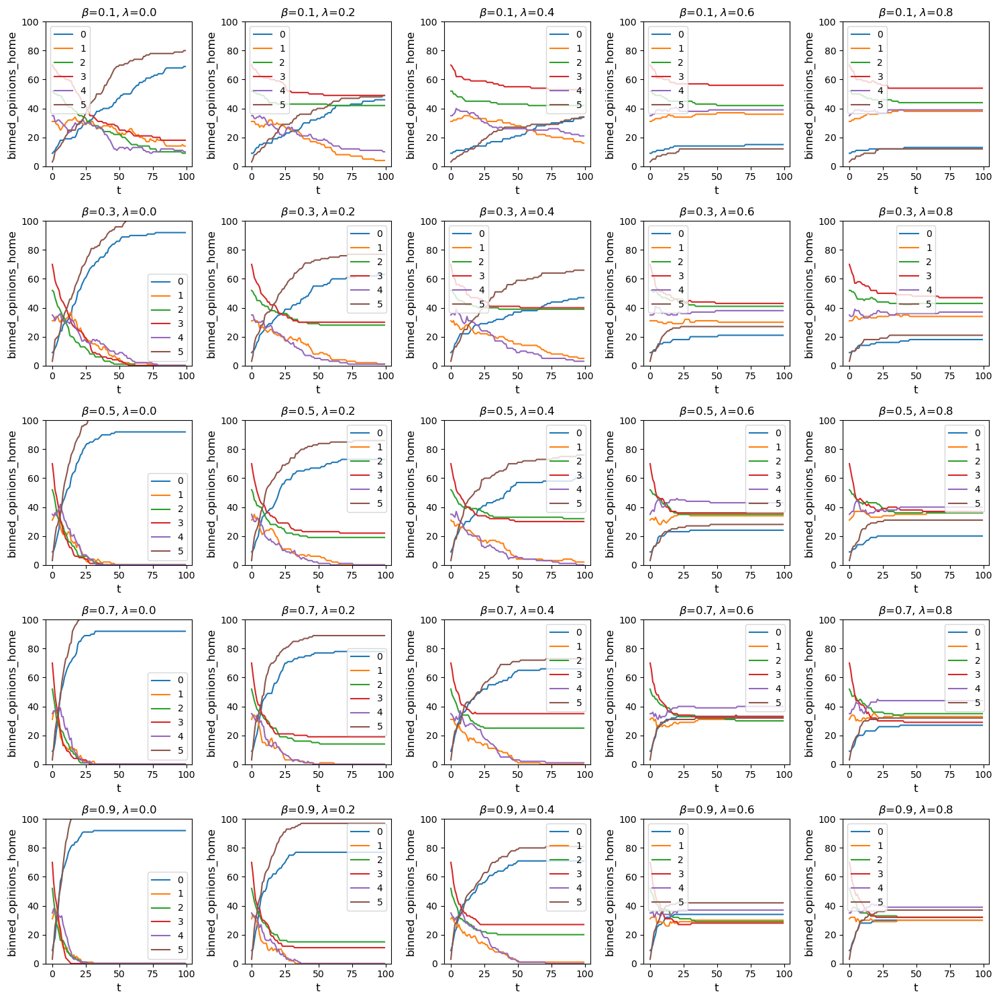

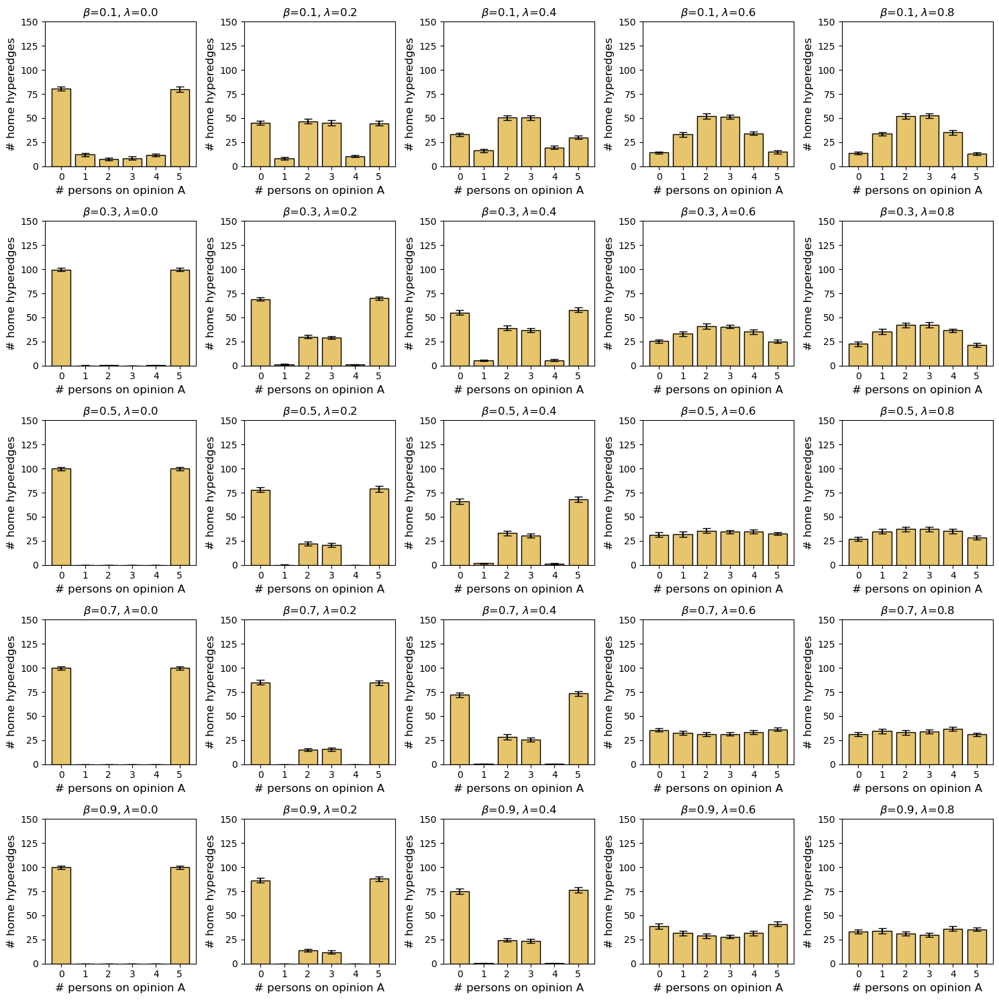

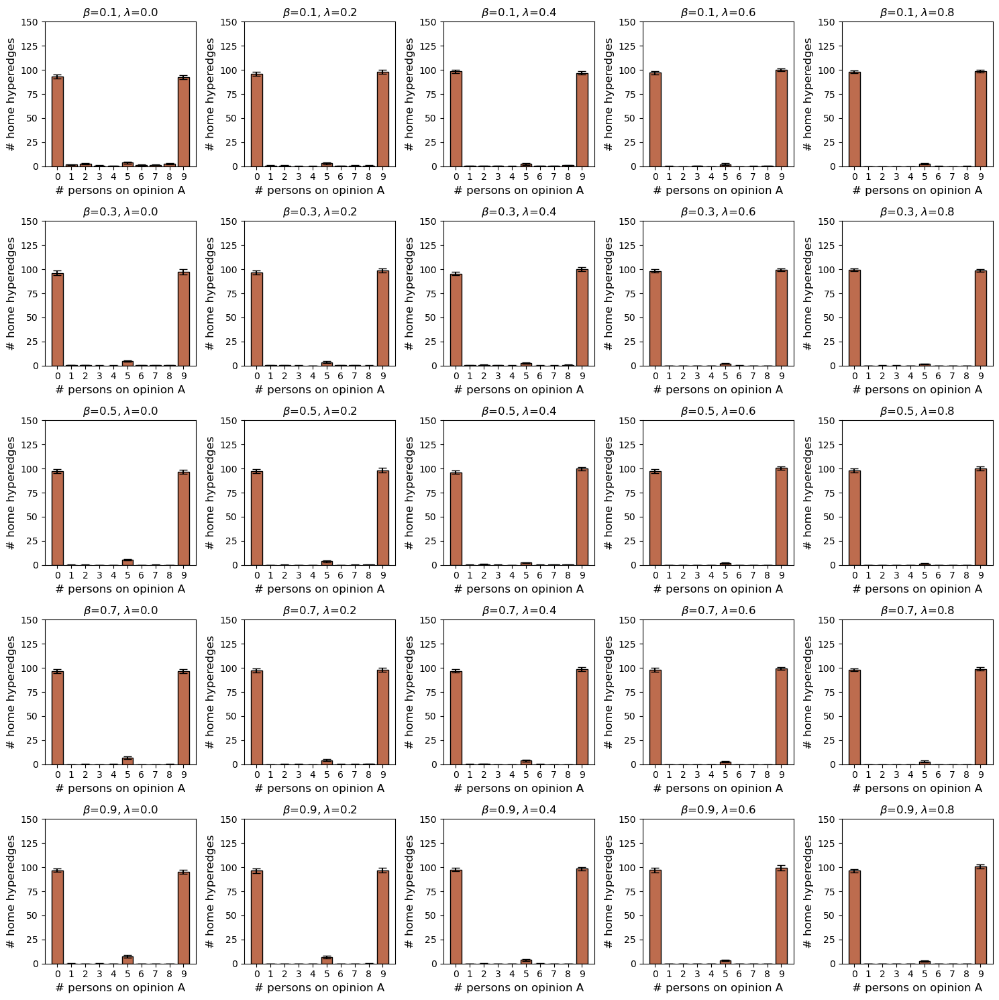

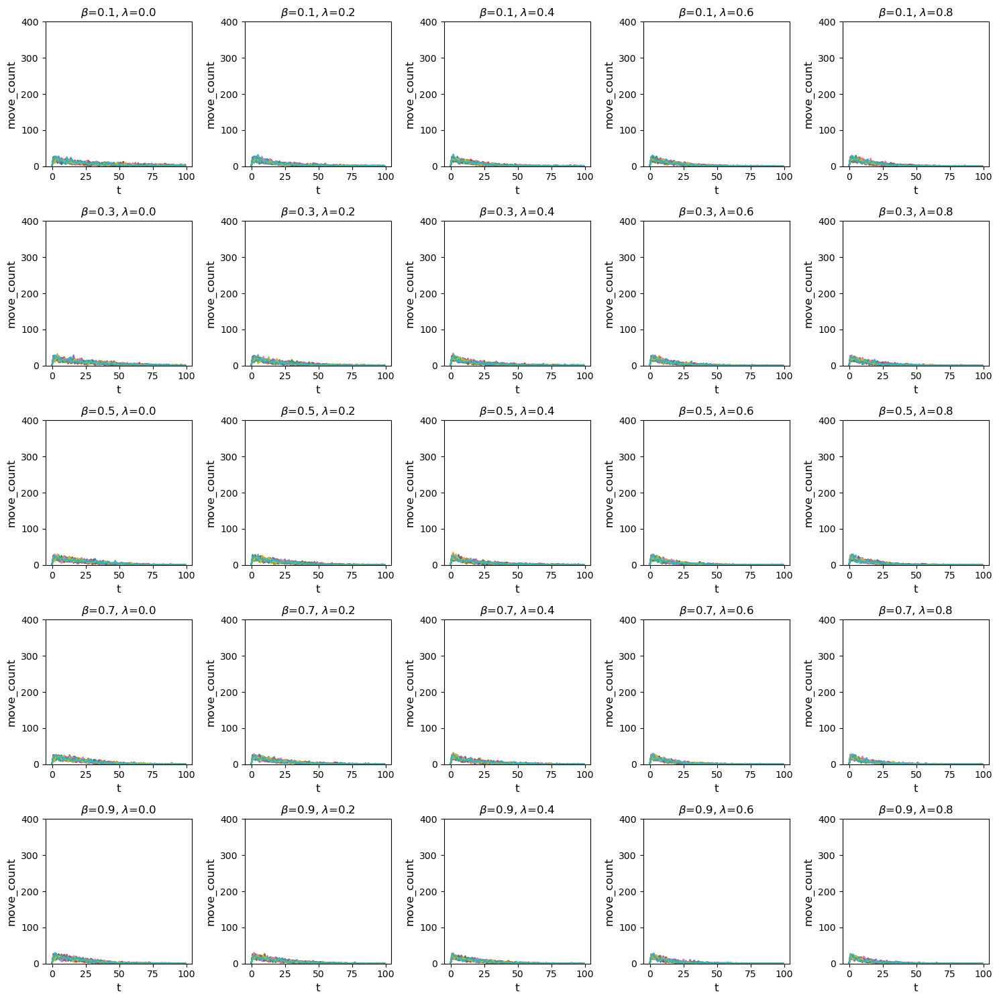

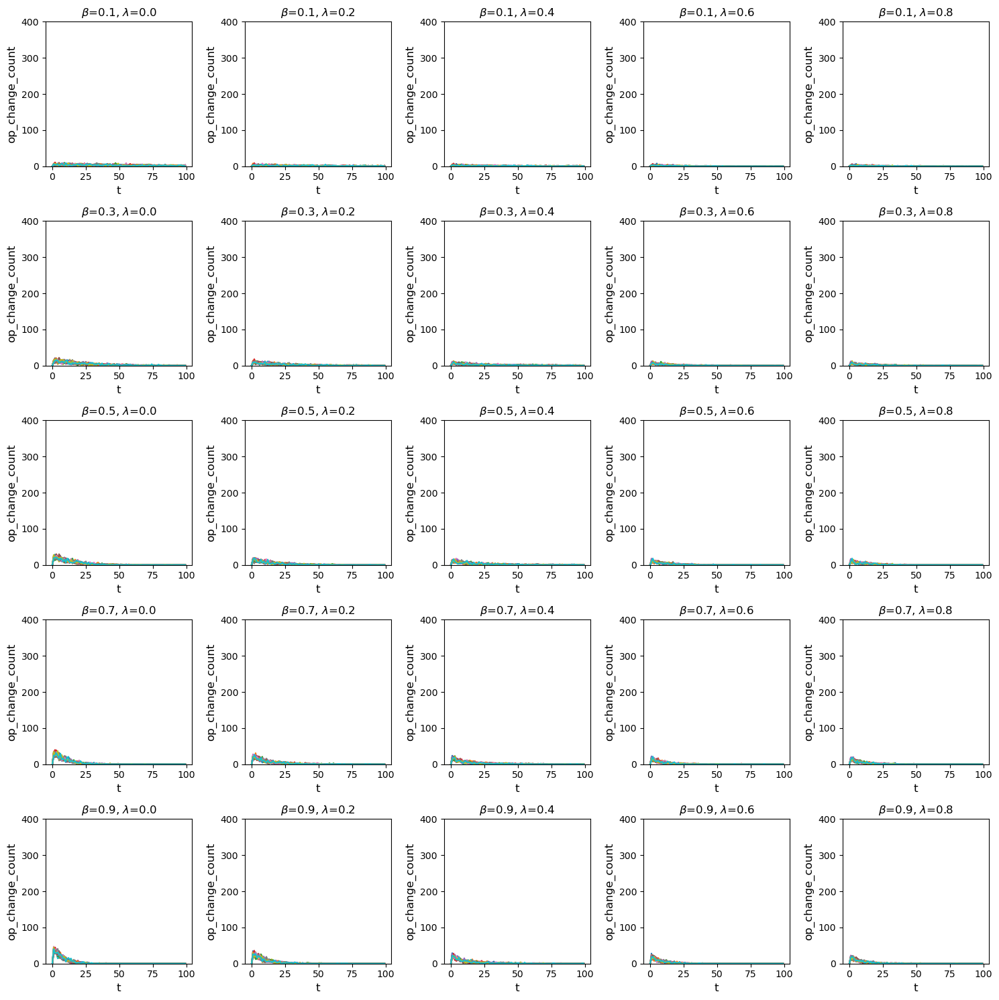

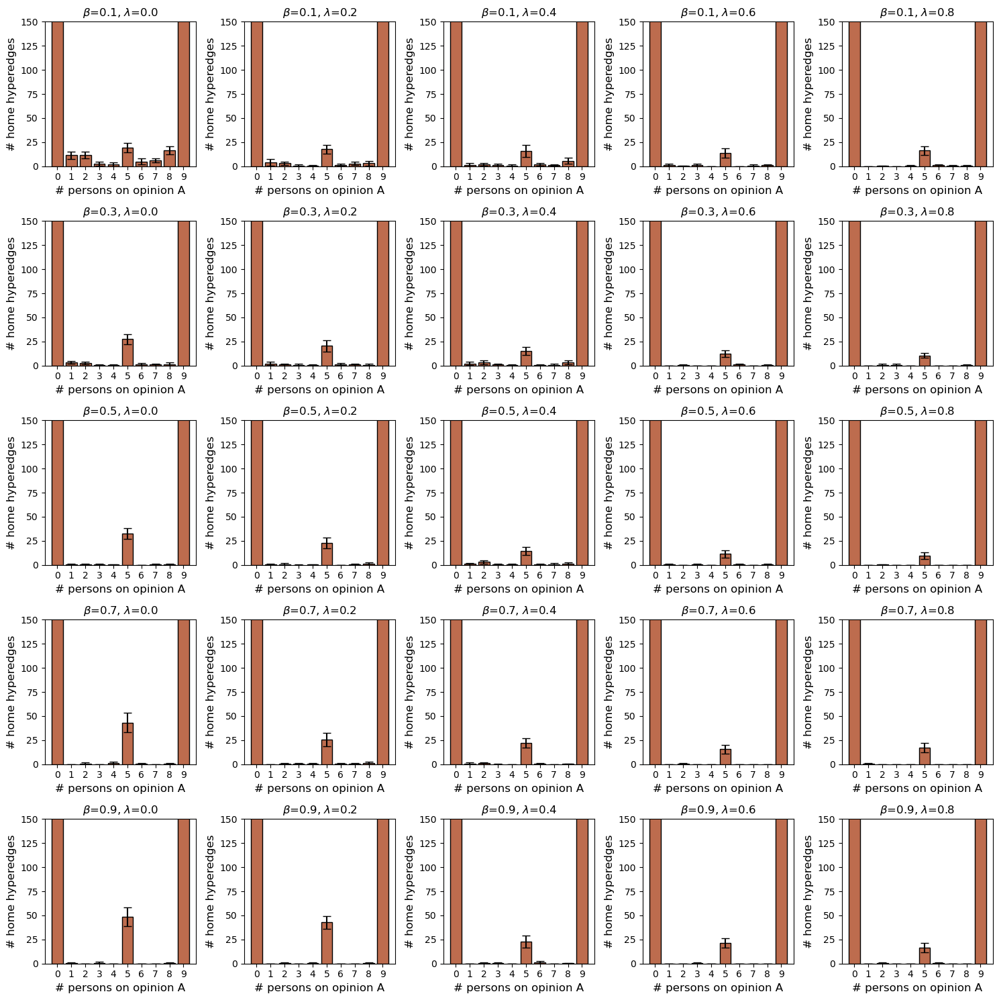

In [46]:
lambdas=np.arange(0,1,0.2)
name2=r'$\lambda$'
plot_time_dynamic(data_l2,'sum_opinion_A',betas,lambdas,r'$\beta$',name2,(0,1000))
plot_time_dynamic(data_l2,'binned_opinions_home',betas,lambdas,r'$\beta$',name2,(0,100), iters=1,legend =True)
hyperedge_opinions(data_l2,betas,lambdas,r'$\beta$',name2,row='binned_opinions_home', color_i=0)
hyperedge_opinions(data_l2,betas,lambdas,r'$\beta$',name2,row='binned_opinions_wp', color_i=1)
plot_time_dynamic(data_l2,'move_count',betas,lambdas,r'$\beta$',name2,(0,400))
plot_time_dynamic(data_l2,'op_change_count',betas,lambdas,r'$\beta$',name2,(0,400))
hyperedge_opinions(data_l2,betas,lambdas,r'$\beta$',name2,row='binned_opinions_wp_pop_sized', color_i=1)


In [52]:
graph_args={'name': 'd_regular', 'args': {'n':1000, 'd':2,'edge size':5, 'distribution':'uniform'}}
data_nonlinq = run_parallel(graph_args, betas=np.arange(0.1,1,0.2), qs=np.arange(0,1,0.2),r1s=[0.5], lambdas=[0.5], endtime=100000,move='majority', iterations=20, processes=50,log_freq=1000, save=False)

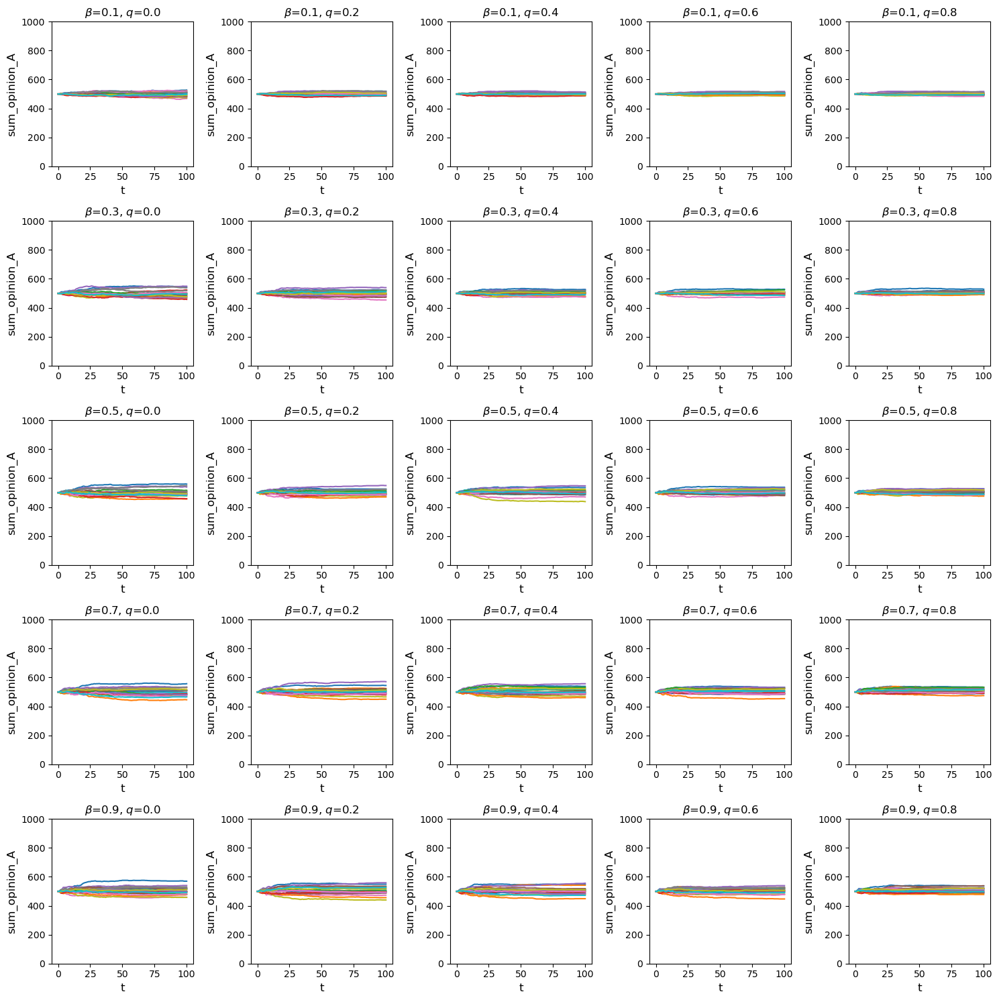

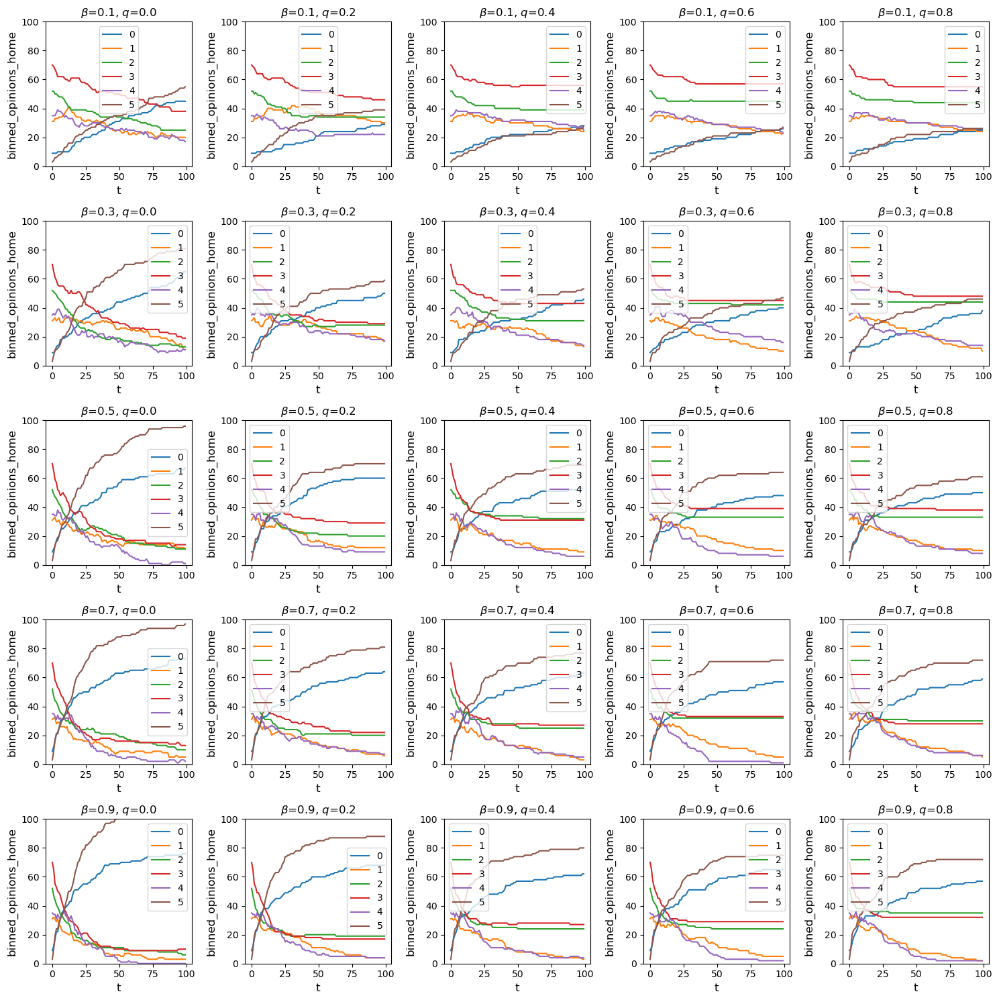

KeyError: 'move_count'

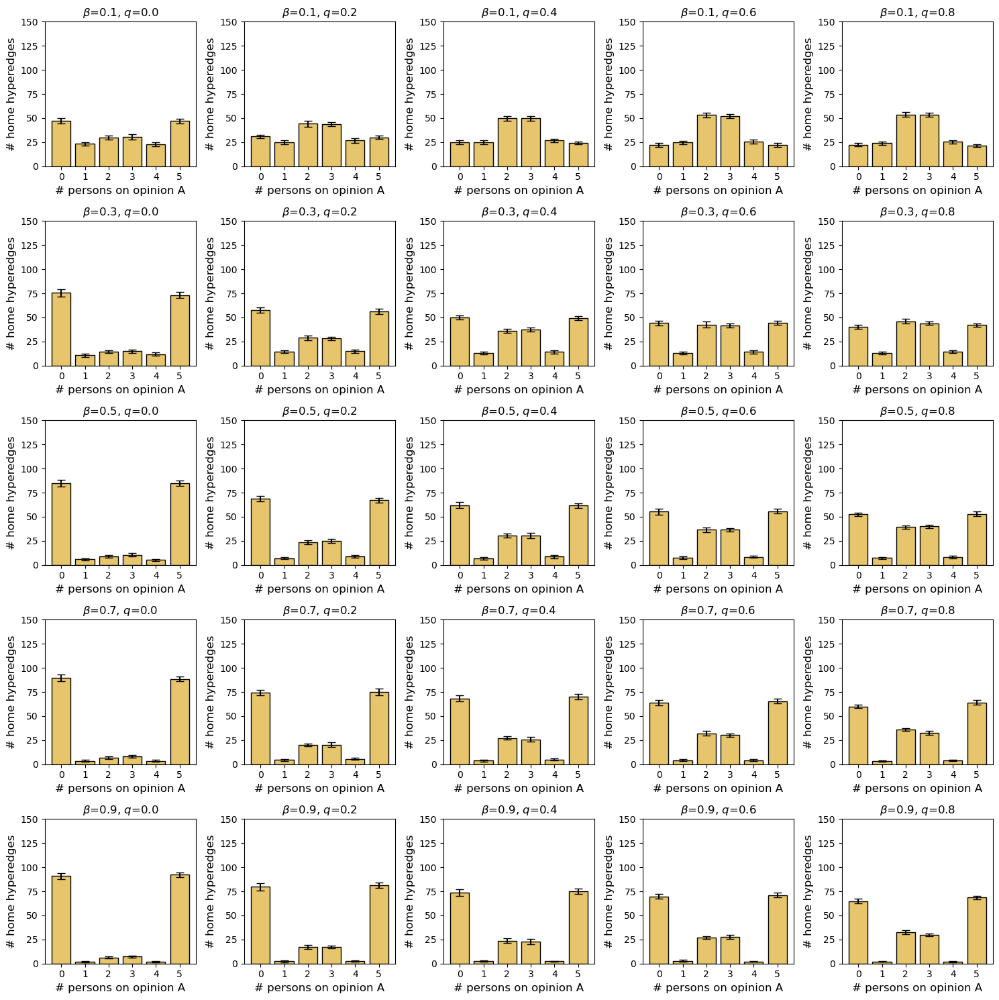

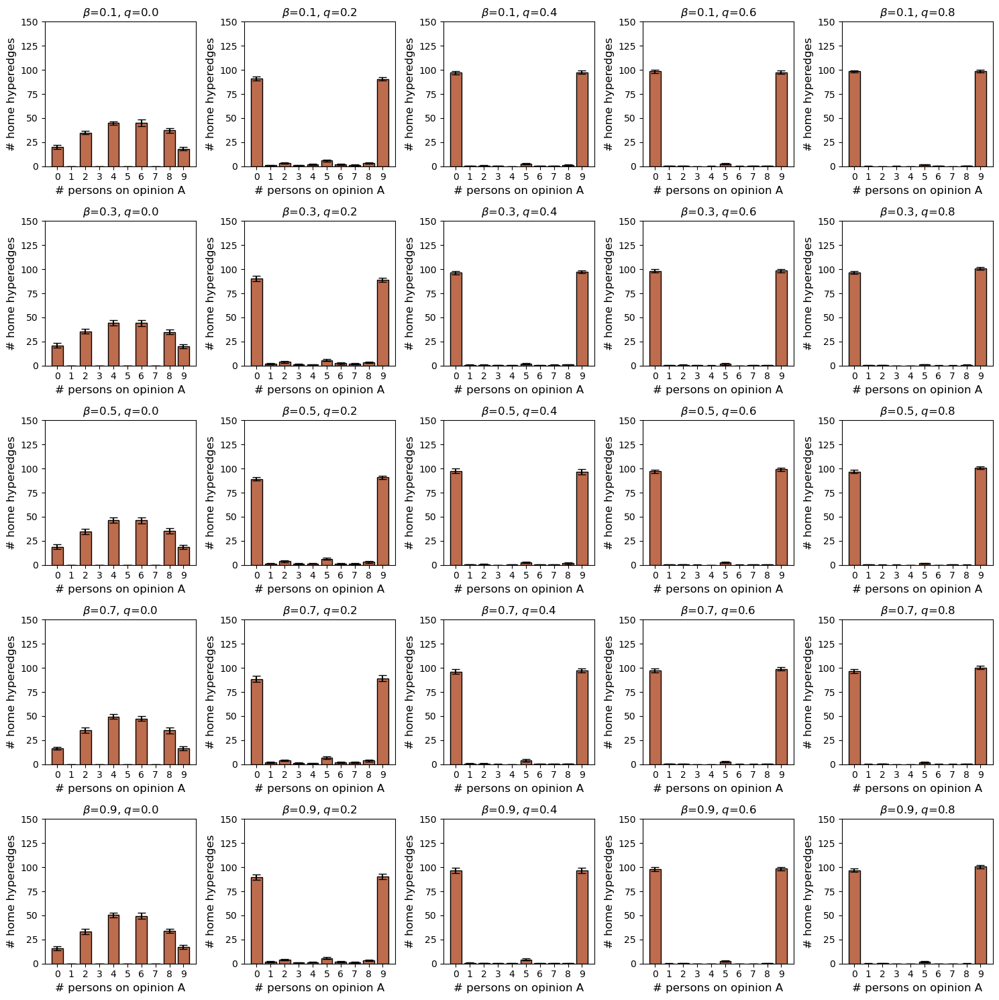

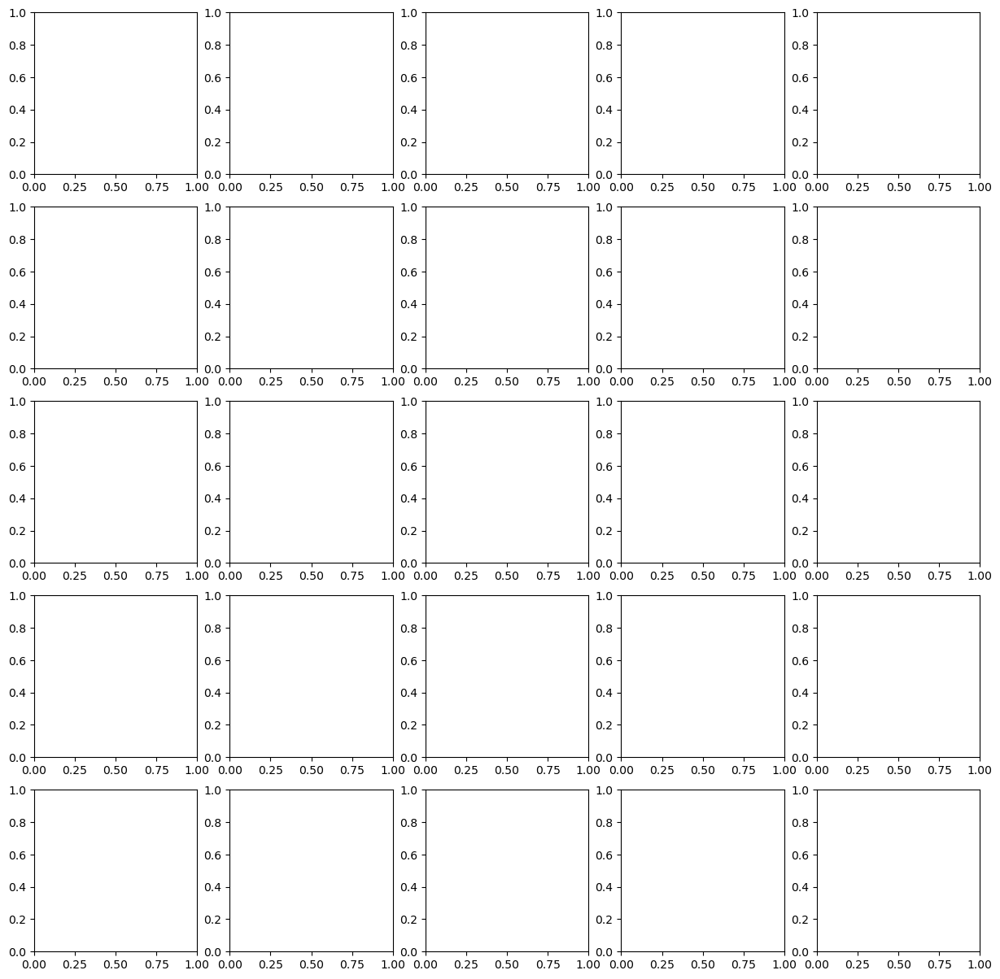

In [53]:
lambdas=np.arange(0,1,0.2)
name2=r'$q$'
plot_time_dynamic(data_nonlinq,'sum_opinion_A',betas,qs,r'$\beta$',name2,(0,1000))
plot_time_dynamic(data_nonlinq,'binned_opinions_home',betas,qs,r'$\beta$',name2,(0,100), iters=1,legend =True)
hyperedge_opinions(data_nonlinq,betas,qs,r'$\beta$',name2,row='binned_opinions_home', color_i=0)
hyperedge_opinions(data_nonlinq,betas,qs,r'$\beta$',name2,row='binned_opinions_wp', color_i=1)
plot_time_dynamic(data_nonlinq,'move_count',betas,lambdas,r'$\beta$',name2,(0,400))
plot_time_dynamic(data_nonlinq,'op_change_count',betas,lambdas,r'$\beta$',name2,(0,400))
#hyperedge_opinions(data_nonlinq,betas,qs,r'$\beta$',name2,row='binned_opinions_wp_pop_sized', color_i=1)


In [2]:
for i in range(1,5):
    print(i)

1
2
3
4
